<a href="https://colab.research.google.com/github/vthavavel/Agriculture/blob/main/JAIT_AgriTabNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install pytorch-tabnet

In [1]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [2]:
import joblib
import os
os.chdir("/content/drive/MyDrive/Agriculture")
!ls

 accuracy_plot.png			    pre_pruned_model.h5
 AgriTabNet_CSSE.ipynb			    pretrained_model.pth
 auto_model				    pruned_accuracy_curve.png
 bar_compare.png			    pruned_loss_curve.png
 Baseline_accuracy_curve.png		    pruned_model.h5
 Baseline_loss_curve.png		    pruned_model_tf
 baseline_model.h5			    pruned_roc_curve.png
 baseline_roc_curve.png			    pruned_weights.h5
 best_model.pt				    PruneGradual_model.h5
 build_agritabnet_apk.py		    PruneOnce_model.h5
'Copy of Crop_recommendation.csv'	    pruning_logs
 crop_model.pkl				    pSparsity_curve.png
 Crop_recommendation.csv		    QAT_gru.tflite
'crop recomm.ipynb'			    QAT.h5
 cv_folds.npz				    quantized_base_model.tflite
 fine_tune_accuracy_loss_curve.png	    quantized_gru_model_float16.tflite
 force_plot.html			    quantized_stripped_model_8.tflite
 gate_ft_best.pt			    quantized_stripped_model.tflite
 Light_DL_Agri.ipynb			    quantized_str_weight_model.tflite
 lime_explanation.png			    quantized_train_pruned_model.tflite


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

df=pd.read_csv('Crop_recommendation.csv')
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


# Extract only the samples of hard crops  

In [ ]:
selected_labels = [
    'jute', 'rice', 'blackgram', 'cotton',
    'lentil', 'maize', 'muskmelon', 'pigeonpeas'
]

df_filtered = df[df['label'].isin(selected_labels)]

df_filtered.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
X = df_filtered.drop('label', axis=1).values
y = df_filtered['label']

le = LabelEncoder()
y = le.fit_transform(y)


In [ ]:
# -----------------------------------
# define model builder
# -----------------------------------
import tensorflow as tf
import keras
def build_lstm_model(input_dim=7, num_classes=22):
    inputs = keras.Input(shape=(input_dim,))

    x = keras.layers.Reshape((input_dim, 1))(inputs)
    x = keras.layers.LSTM(48)(x)
    x = keras.layers.Dense(24, activation="gelu")(x)
    outputs = keras.layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [ ]:
import keras
from keras.layers import LeakyReLU

def build_cnn_model(input_dim=7, num_classes=22):
    inputs = keras.Input(shape=(input_dim,))
    x = keras.layers.Reshape((input_dim, 1))(inputs)

    # First Conv1D block
    x = keras.layers.Conv1D(128, kernel_size=3, padding="same")(x)
    x = LeakyReLU(negative_slope=0.1)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.MaxPooling1D(pool_size=2)(x)

    # Second Conv1D block
    x = keras.layers.Conv1D(256, kernel_size=2, padding="same")(x)
    x = LeakyReLU(negative_slope=0.1)(x)
    x = keras.layers.BatchNormalization()(x)

    # Global pooling
    x = keras.layers.GlobalAveragePooling1D()(x)

    # Dense layers
    x = keras.layers.Dense(64, activation="relu")(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Dense(32, activation="relu")(x)

    # Output layer
    outputs = keras.layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.00005),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [8]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# --------------------------------------------------
# Context gating network
# --------------------------------------------------
class ResidualContextGate(nn.Module):
    def __init__(self, input_dim, hidden_dim=8, alpha=0.3):
        super().__init__()
        self.alpha = alpha
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        gate = self.net(x)
        x_ctx = x * (1.0 + self.alpha * gate)
        return x_ctx, gate

# --------------------------------------------------
# Small classifier used to train the context gate
# --------------------------------------------------
class ContextClassifier(nn.Module):
    def __init__(self, input_dim, num_classes, hidden_dim=8, alpha=0.3):
        super().__init__()
        self.gate = ResidualContextGate(input_dim, hidden_dim, alpha)
        self.head = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        x_ctx, gate = self.gate(x)
        logits = self.head(x_ctx)
        return logits, x_ctx, gate

# Fixed CV splits

In [ ]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate identical folds for all models
cv_folds = list(skf.split(X, y))

# Optional: Save fold indices for reproducibility
np.savez(
    "cv_folds.npz",
    **{
        f"train_{i+1}": train_idx
        for i, (train_idx, test_idx) in enumerate(cv_folds)
    },
    **{
        f"test_{i+1}": test_idx
        for i, (train_idx, test_idx) in enumerate(cv_folds)
    }
)

# RF

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
import numpy as np

# Load the same folds used for other models
#saved = np.load("/content/drive/MyDrive/Agriculture/cv_folds.npz")



rf_acc_scores = []
rf_prec_scores = []
rf_rec_scores = []
rf_f1_scores = []

for fold_no, (train_idx, test_idx) in enumerate(cv_folds, start=1):

    print(f"\n========== Fold {fold_no} ==========")

    X_train_fold, X_test_fold = X[train_idx], X[test_idx]
    y_train_fold, y_test_fold = y[train_idx], y[test_idx]

    # Use the same fold-specific preprocessing
    scaler = StandardScaler()
    X_train_fold = scaler.fit_transform(X_train_fold)
    X_test_fold = scaler.transform(X_test_fold)

    # Train Random Forest
    rf = RandomForestClassifier(random_state=42)
    rf.fit(X_train_fold, y_train_fold)

    # Predict
    y_pred = rf.predict(X_test_fold)

    # Metrics
    acc = accuracy_score(y_test_fold, y_pred)
    prec = precision_score(y_test_fold, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test_fold, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test_fold, y_pred, average='weighted', zero_division=0)

    rf_acc_scores.append(acc)
    rf_prec_scores.append(prec)
    rf_rec_scores.append(rec)
    rf_f1_scores.append(f1)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

print("\n===== Random Forest 5-Fold CV Results =====")
print(f"Accuracy : {np.mean(rf_acc_scores):.4f} ± {np.std(rf_acc_scores):.4f}")
print(f"Precision: {np.mean(rf_prec_scores):.4f} ± {np.std(rf_prec_scores):.4f}")
print(f"Recall   : {np.mean(rf_rec_scores):.4f} ± {np.std(rf_rec_scores):.4f}")
print(f"F1-score : {np.mean(rf_f1_scores):.4f} ± {np.std(rf_f1_scores):.4f}")


========== Fold 1 ==========
Accuracy : 0.9875
Precision: 0.9886
Recall   : 0.9875
F1-score : 0.9875

========== Fold 2 ==========
Accuracy : 0.9812
Precision: 0.9815
Recall   : 0.9812
F1-score : 0.9812

========== Fold 3 ==========
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

========== Fold 4 ==========
Accuracy : 0.9938
Precision: 0.9940
Recall   : 0.9938
F1-score : 0.9937

========== Fold 5 ==========
Accuracy : 0.9812
Precision: 0.9827
Recall   : 0.9812
F1-score : 0.9812

===== Random Forest 5-Fold CV Results =====
Accuracy : 0.9887 ± 0.0073
Precision: 0.9894 ± 0.0070
Recall   : 0.9887 ± 0.0073
F1-score : 0.9887 ± 0.0073


In [ ]:
import joblib
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/CA_TabNet_Results/Saved_Models")
save_dir.mkdir(parents=True, exist_ok=True)

# Save trained RF model
joblib.dump(rf, save_dir / "RF_model.pkl")

print("RF model saved successfully.")

RF model saved successfully.


# XGboost

In [ ]:

# !pip install xgboost

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
import numpy as np

xgb_acc_scores = []
xgb_prec_scores = []
xgb_rec_scores = []
xgb_f1_scores = []

for fold_no, (train_idx, test_idx) in enumerate(cv_folds, start=1):

    print(f"\n========== Fold {fold_no} ==========")

    X_train_fold, X_test_fold = X[train_idx], X[test_idx]
    y_train_fold, y_test_fold = y[train_idx], y[test_idx]

    # Same fold-specific preprocessing
    scaler = StandardScaler()
    X_train_fold = scaler.fit_transform(X_train_fold)
    X_test_fold = scaler.transform(X_test_fold)

    # Train XGBoost
    xgb = XGBClassifier(
        objective="multi:softprob",
        num_class=22,
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    xgb.fit(X_train_fold, y_train_fold)

    # Predict
    y_pred = xgb.predict(X_test_fold)

    # Metrics
    acc = accuracy_score(y_test_fold, y_pred)
    prec = precision_score(y_test_fold, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test_fold, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test_fold, y_pred, average='weighted', zero_division=0)

    xgb_acc_scores.append(acc)
    xgb_prec_scores.append(prec)
    xgb_rec_scores.append(rec)
    xgb_f1_scores.append(f1)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

print("\n===== XGBoost 5-Fold CV Results =====")
print(f"Accuracy : {np.mean(xgb_acc_scores):.4f} ± {np.std(xgb_acc_scores):.4f}")
print(f"Precision: {np.mean(xgb_prec_scores):.4f} ± {np.std(xgb_prec_scores):.4f}")
print(f"Recall   : {np.mean(xgb_rec_scores):.4f} ± {np.std(xgb_rec_scores):.4f}")
print(f"F1-score : {np.mean(xgb_f1_scores):.4f} ± {np.std(xgb_f1_scores):.4f}")



========== Fold 1 ==========
Accuracy : 0.9875
Precision: 0.9886
Recall   : 0.9875
F1-score : 0.9875

========== Fold 2 ==========
Accuracy : 0.9812
Precision: 0.9815
Recall   : 0.9812
F1-score : 0.9812

========== Fold 3 ==========
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

========== Fold 4 ==========
Accuracy : 0.9938
Precision: 0.9940
Recall   : 0.9938
F1-score : 0.9937

========== Fold 5 ==========
Accuracy : 0.9750
Precision: 0.9756
Recall   : 0.9750
F1-score : 0.9750

===== XGBoost 5-Fold CV Results =====
Accuracy : 0.9875 ± 0.0088
Precision: 0.9880 ± 0.0087
Recall   : 0.9875 ± 0.0088
F1-score : 0.9875 ± 0.0088


In [ ]:
import joblib
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/CA_TabNet_Results/Saved_Models")
save_dir.mkdir(parents=True, exist_ok=True)

# Save trained XGBoost model
joblib.dump(xgb, save_dir / "XGBoost_model.pkl")

print("XGBoost model saved successfully.")

XGBoost model saved successfully.


# SVM(RBF)

In [ ]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
import numpy as np

svm_acc_scores = []
svm_prec_scores = []
svm_rec_scores = []
svm_f1_scores = []

for fold_no, (train_idx, test_idx) in enumerate(cv_folds, start=1):

    print(f"\n========== Fold {fold_no} ==========")

    X_train_fold, X_test_fold = X[train_idx], X[test_idx]
    y_train_fold, y_test_fold = y[train_idx], y[test_idx]

    # Fold-specific preprocessing
    scaler = StandardScaler()
    X_train_fold = scaler.fit_transform(X_train_fold)
    X_test_fold = scaler.transform(X_test_fold)

    # Train SVM with RBF kernel
    svm = SVC(
        kernel="rbf",
        C=10.0,
        gamma="scale",
        random_state=42
    )

    svm.fit(X_train_fold, y_train_fold)

    # Predict
    y_pred = svm.predict(X_test_fold)

    # Metrics
    acc = accuracy_score(y_test_fold, y_pred)
    prec = precision_score(y_test_fold, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test_fold, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test_fold, y_pred, average='weighted', zero_division=0)

    svm_acc_scores.append(acc)
    svm_prec_scores.append(prec)
    svm_rec_scores.append(rec)
    svm_f1_scores.append(f1)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

print("\n===== SVM (RBF) 5-Fold CV Results =====")
print(f"Accuracy : {np.mean(svm_acc_scores):.4f} ± {np.std(svm_acc_scores):.4f}")
print(f"Precision: {np.mean(svm_prec_scores):.4f} ± {np.std(svm_prec_scores):.4f}")
print(f"Recall   : {np.mean(svm_rec_scores):.4f} ± {np.std(svm_rec_scores):.4f}")
print(f"F1-score : {np.mean(svm_f1_scores):.4f} ± {np.std(svm_f1_scores):.4f}")



========== Fold 1 ==========
Accuracy : 0.9563
Precision: 0.9625
Recall   : 0.9563
F1-score : 0.9558

========== Fold 2 ==========
Accuracy : 0.9812
Precision: 0.9815
Recall   : 0.9812
F1-score : 0.9812

========== Fold 3 ==========
Accuracy : 0.9812
Precision: 0.9815
Recall   : 0.9812
F1-score : 0.9812

========== Fold 4 ==========
Accuracy : 0.9812
Precision: 0.9815
Recall   : 0.9812
F1-score : 0.9812

========== Fold 5 ==========
Accuracy : 0.9688
Precision: 0.9690
Recall   : 0.9688
F1-score : 0.9687

===== SVM (RBF) 5-Fold CV Results =====
Accuracy : 0.9738 ± 0.0100
Precision: 0.9752 ± 0.0080
Recall   : 0.9738 ± 0.0100
F1-score : 0.9736 ± 0.0102


In [ ]:

import joblib
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/CA_TabNet_Results/Saved_Models")
save_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(svm, save_dir / "SVM_RBF_model.pkl")
joblib.dump(scaler, save_dir / "SVM_RBF_scaler.pkl")

print("SVM model and scaler saved successfully.")


SVM model and scaler saved successfully.


In [ ]:

import joblib
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/CA_TabNet_Results/Saved_Models")
save_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(svm, save_dir / "SVM_RBF_model.pkl")
joblib.dump(scaler, save_dir / "SVM_RBF_scaler.pkl")

print("SVM model and scaler saved successfully.")


SVM model and scaler saved successfully.


# MLP

In [ ]:

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
import numpy as np

mlp_acc_scores = []
mlp_prec_scores = []
mlp_rec_scores = []
mlp_f1_scores = []

for fold_no, (train_idx, test_idx) in enumerate(cv_folds, start=1):

    print(f"\n========== Fold {fold_no} ==========")

    X_train_fold, X_test_fold = X[train_idx], X[test_idx]
    y_train_fold, y_test_fold = y[train_idx], y[test_idx]

    # Fold-specific preprocessing
    scaler = StandardScaler()
    X_train_fold = scaler.fit_transform(X_train_fold)
    X_test_fold = scaler.transform(X_test_fold)

    # Train MLP
    mlp = MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        batch_size=128,
        max_iter=200,
        early_stopping=True,
        validation_fraction=0.2,
        n_iter_no_change=20,
        random_state=42
    )

    mlp.fit(X_train_fold, y_train_fold)

    # Predict
    y_pred = mlp.predict(X_test_fold)

    # Metrics
    acc = accuracy_score(y_test_fold, y_pred)
    prec = precision_score(y_test_fold, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test_fold, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test_fold, y_pred, average='weighted', zero_division=0)

    mlp_acc_scores.append(acc)
    mlp_prec_scores.append(prec)
    mlp_rec_scores.append(rec)
    mlp_f1_scores.append(f1)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

print("\n===== MLP 5-Fold CV Results =====")
print(f"Accuracy : {np.mean(mlp_acc_scores):.4f} ± {np.std(mlp_acc_scores):.4f}")
print(f"Precision: {np.mean(mlp_prec_scores):.4f} ± {np.std(mlp_prec_scores):.4f}")
print(f"Recall   : {np.mean(mlp_rec_scores):.4f} ± {np.std(mlp_rec_scores):.4f}")
print(f"F1-score : {np.mean(mlp_f1_scores):.4f} ± {np.std(mlp_f1_scores):.4f}")



========== Fold 1 ==========
Accuracy : 0.9062
Precision: 0.9084
Recall   : 0.9062
F1-score : 0.9064

========== Fold 2 ==========
Accuracy : 0.9375
Precision: 0.9411
Recall   : 0.9375
F1-score : 0.9376

========== Fold 3 ==========
Accuracy : 0.9313
Precision: 0.9331
Recall   : 0.9313
F1-score : 0.9310

========== Fold 4 ==========
Accuracy : 0.9062
Precision: 0.9130
Recall   : 0.9062
F1-score : 0.9057

========== Fold 5 ==========
Accuracy : 0.9437
Precision: 0.9440
Recall   : 0.9437
F1-score : 0.9437

===== MLP 5-Fold CV Results =====
Accuracy : 0.9250 ± 0.0158
Precision: 0.9279 ± 0.0146
Recall   : 0.9250 ± 0.0158
F1-score : 0.9249 ± 0.0159


In [ ]:

import joblib
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/CA_TabNet_Results/Saved_Models")
save_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(mlp, save_dir / "MLP_model.pkl")
joblib.dump(scaler, save_dir / "MLP_scaler.pkl")

print("MLP model and scaler saved successfully.")


MLP model and scaler saved successfully.


# LSTM

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
import numpy as np
import tensorflow as tf
from tensorflow import keras

lstm_acc_scores = []
lstm_prec_scores = []
lstm_rec_scores = []
lstm_f1_scores = []

for fold_no, (train_idx, test_idx) in enumerate(cv_folds, start=1):

    print(f"\n========== Fold {fold_no} ==========")

    X_train_outer, X_test_fold = X[train_idx], X[test_idx]
    y_train_outer, y_test_fold = y[train_idx], y[test_idx]

    # Internal validation split for early stopping
    X_train_inner, X_val, y_train_inner, y_val = train_test_split(
        X_train_outer,
        y_train_outer,
        test_size=0.2,
        stratify=y_train_outer,
        random_state=42
    )

    # Fit scaler on training data only
    scaler = StandardScaler()
    X_train_inner = scaler.fit_transform(X_train_inner).astype(np.float32)
    X_val = scaler.transform(X_val).astype(np.float32)
    X_test_fold = scaler.transform(X_test_fold).astype(np.float32)

    # Fresh LSTM model for each fold
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold_no)

    lstm = build_lstm_model(
        input_dim=X_train_inner.shape[1],
        num_classes=len(np.unique(y))
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = lstm.fit(
        X_train_inner,
        y_train_inner,
        epochs=100,
        batch_size=128,
        validation_data=(X_val, y_val),
        callbacks=[early_stop],
        verbose=0
    )

    # Evaluate only on the untouched test fold
    y_prob = lstm.predict(X_test_fold, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    acc = accuracy_score(y_test_fold, y_pred)
    prec = precision_score(
        y_test_fold, y_pred, average='weighted', zero_division=0
    )
    rec = recall_score(
        y_test_fold, y_pred, average='weighted', zero_division=0
    )
    f1 = f1_score(
        y_test_fold, y_pred, average='weighted', zero_division=0
    )

    lstm_acc_scores.append(acc)
    lstm_prec_scores.append(prec)
    lstm_rec_scores.append(rec)
    lstm_f1_scores.append(f1)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

print("\n===== LSTM 5-Fold CV Results =====")
print(f"Accuracy : {np.mean(lstm_acc_scores):.4f} ± {np.std(lstm_acc_scores):.4f}")
print(f"Precision: {np.mean(lstm_prec_scores):.4f} ± {np.std(lstm_prec_scores):.4f}")
print(f"Recall   : {np.mean(lstm_rec_scores):.4f} ± {np.std(lstm_rec_scores):.4f}")
print(f"F1-score : {np.mean(lstm_f1_scores):.4f} ± {np.std(lstm_f1_scores):.4f}")



========== Fold 1 ==========
Accuracy : 0.9062
Precision: 0.9089
Recall   : 0.9062
F1-score : 0.9059

========== Fold 2 ==========
Accuracy : 0.9375
Precision: 0.9408
Recall   : 0.9375
F1-score : 0.9380

========== Fold 3 ==========
Accuracy : 0.9688
Precision: 0.9718
Recall   : 0.9688
F1-score : 0.9686

========== Fold 4 ==========
Accuracy : 0.9062
Precision: 0.9145
Recall   : 0.9062
F1-score : 0.9063

========== Fold 5 ==========
Accuracy : 0.9563
Precision: 0.9614
Recall   : 0.9563
F1-score : 0.9560

===== LSTM 5-Fold CV Results =====
Accuracy : 0.9350 ± 0.0255
Precision: 0.9395 ± 0.0249
Recall   : 0.9350 ± 0.0255
F1-score : 0.9350 ± 0.0255


In [ ]:
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/CA_TabNet_Results/Saved_Models")
save_dir.mkdir(parents=True, exist_ok=True)

# Save trained LSTM model
lstm.save(str(save_dir / "LSTM_model.keras"))

print("LSTM model saved successfully.")

LSTM model saved successfully.


# CNN

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
import numpy as np
import tensorflow as tf
from tensorflow import keras

cnn_acc_scores = []
cnn_prec_scores = []
cnn_rec_scores = []
cnn_f1_scores = []

for fold_no, (train_idx, test_idx) in enumerate(cv_folds, start=1):

    print(f"\n========== Fold {fold_no} ==========")

    X_train_outer, X_test_fold = X[train_idx], X[test_idx]
    y_train_outer, y_test_fold = y[train_idx], y[test_idx]

    # Internal validation split (outer test fold remains untouched)
    X_train_inner, X_val, y_train_inner, y_val = train_test_split(
        X_train_outer,
        y_train_outer,
        test_size=0.2,
        stratify=y_train_outer,
        random_state=42
    )

    # Fit scaler on inner training data only
    scaler = StandardScaler()
    X_train_inner = scaler.fit_transform(X_train_inner).astype(np.float32)
    X_val = scaler.transform(X_val).astype(np.float32)
    X_test_fold = scaler.transform(X_test_fold).astype(np.float32)

    # Fresh CNN model for each fold
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold_no)

    cnn = build_cnn_model(
        input_dim=X_train_inner.shape[1],
        num_classes=len(np.unique(y))
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    )

    history = cnn.fit(
        X_train_inner,
        y_train_inner,
        epochs=100,
        batch_size=128,
        validation_data=(X_val, y_val),
        callbacks=[early_stop],
        verbose=0
    )

    # Final evaluation on the independent test fold
    y_prob = cnn.predict(X_test_fold, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    acc = accuracy_score(y_test_fold, y_pred)
    prec = precision_score(
        y_test_fold, y_pred, average='weighted', zero_division=0
    )
    rec = recall_score(
        y_test_fold, y_pred, average='weighted', zero_division=0
    )
    f1 = f1_score(
        y_test_fold, y_pred, average='weighted', zero_division=0
    )

    cnn_acc_scores.append(acc)
    cnn_prec_scores.append(prec)
    cnn_rec_scores.append(rec)
    cnn_f1_scores.append(f1)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

print("\n===== CNN 5-Fold CV Results =====")
print(f"Accuracy : {np.mean(cnn_acc_scores):.4f} ± {np.std(cnn_acc_scores):.4f}")
print(f"Precision: {np.mean(cnn_prec_scores):.4f} ± {np.std(cnn_prec_scores):.4f}")
print(f"Recall   : {np.mean(cnn_rec_scores):.4f} ± {np.std(cnn_rec_scores):.4f}")
print(f"F1-score : {np.mean(cnn_f1_scores):.4f} ± {np.std(cnn_f1_scores):.4f}")



========== Fold 1 ==========
Accuracy : 0.7812
Precision: 0.8462
Recall   : 0.7812
F1-score : 0.7578

========== Fold 2 ==========
Accuracy : 0.8250
Precision: 0.8668
Recall   : 0.8250
F1-score : 0.8174

========== Fold 3 ==========
Accuracy : 0.8000
Precision: 0.8635
Recall   : 0.8000
F1-score : 0.7882

========== Fold 4 ==========
Accuracy : 0.7063
Precision: 0.8307
Recall   : 0.7063
F1-score : 0.6844

========== Fold 5 ==========
Accuracy : 0.6750
Precision: 0.7876
Recall   : 0.6750
F1-score : 0.6703

===== CNN 5-Fold CV Results =====
Accuracy : 0.7575 ± 0.0572
Precision: 0.8390 ± 0.0287
Recall   : 0.7575 ± 0.0572
F1-score : 0.7436 ± 0.0575


#Tabnet

In [ ]:

import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
from pytorch_tabnet.tab_model import TabNetClassifier

# Load the same folds used for other models
#saved = np.load("/content/drive/MyDrive/cv_folds.npz")

#cv_folds = [
#    (saved[f"train_{i}"], saved[f"test_{i}"])
#    for i in range(1, 6)
#]

tab_acc_scores = []
tab_prec_scores = []
tab_rec_scores = []
tab_f1_scores = []

for fold_no, (train_idx, test_idx) in enumerate(cv_folds, start=1):

    print(f"\n========== Fold {fold_no} ==========")

    X_train_outer, X_test_fold = X[train_idx], X[test_idx]
    y_train_outer, y_test_fold = y[train_idx], y[test_idx]

    # Internal validation split
    X_train_inner, X_val, y_train_inner, y_val = train_test_split(
        X_train_outer,
        y_train_outer,
        test_size=0.2,
        stratify=y_train_outer,
        random_state=42
    )

    # Fit scaler using training data only
    scaler = StandardScaler()
    X_train_inner = scaler.fit_transform(X_train_inner).astype(np.float32)
    X_val = scaler.transform(X_val).astype(np.float32)
    X_test_fold = scaler.transform(X_test_fold).astype(np.float32)

    # Fresh TabNet model for each fold
    torch.manual_seed(42 + fold_no)

    tabnet_model = TabNetClassifier(
        n_d=8,
        n_a=32,
        n_steps=10,
        gamma=1.3,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=2e-2),
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        scheduler_params={"step_size": 10, "gamma": 0.9},
        mask_type="sparsemax",
        seed=42 + fold_no
    )

    # Training with internal validation only
    tabnet_model.fit(
        X_train_inner,
        y_train_inner,
        eval_set=[(X_val, y_val)],
        eval_name=["valid"],
        eval_metric=["accuracy"],
        max_epochs=100,
        patience=10,
        batch_size=128,
        virtual_batch_size=32,
        num_workers=0,
        drop_last=False
    )

    # Evaluate on untouched outer test fold
    y_pred = tabnet_model.predict(X_test_fold)

    acc = accuracy_score(y_test_fold, y_pred)
    prec = precision_score(
        y_test_fold, y_pred, average="weighted", zero_division=0
    )
    rec = recall_score(
        y_test_fold, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test_fold, y_pred, average="weighted", zero_division=0
    )

    tab_acc_scores.append(acc)
    tab_prec_scores.append(prec)
    tab_rec_scores.append(rec)
    tab_f1_scores.append(f1)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

print("\n===== TabNet 5-Fold CV Results =====")
print(f"Accuracy : {np.mean(tab_acc_scores):.4f} ± {np.std(tab_acc_scores):.4f}")
print(f"Precision: {np.mean(tab_prec_scores):.4f} ± {np.std(tab_prec_scores):.4f}")
print(f"Recall   : {np.mean(tab_rec_scores):.4f} ± {np.std(tab_rec_scores):.4f}")
print(f"F1-score : {np.mean(tab_f1_scores):.4f} ± {np.std(tab_f1_scores):.4f}")



========== Fold 1 ==========


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 2.74189 | valid_accuracy: 0.28125 |  0:00:00s
epoch 1  | loss: 1.54874 | valid_accuracy: 0.53125 |  0:00:00s
epoch 2  | loss: 1.07725 | valid_accuracy: 0.71094 |  0:00:01s
epoch 3  | loss: 0.78432 | valid_accuracy: 0.75    |  0:00:01s
epoch 4  | loss: 0.73057 | valid_accuracy: 0.80469 |  0:00:02s
epoch 5  | loss: 0.63041 | valid_accuracy: 0.8125  |  0:00:02s
epoch 6  | loss: 0.58414 | valid_accuracy: 0.80469 |  0:00:03s
epoch 7  | loss: 0.53348 | valid_accuracy: 0.82031 |  0:00:05s
epoch 8  | loss: 0.4673  | valid_accuracy: 0.86719 |  0:00:06s
epoch 9  | loss: 0.46809 | valid_accuracy: 0.91406 |  0:00:07s
epoch 10 | loss: 0.30826 | valid_accuracy: 0.91406 |  0:00:08s
epoch 11 | loss: 0.3989  | valid_accuracy: 0.86719 |  0:00:08s
epoch 12 | loss: 0.34492 | valid_accuracy: 0.91406 |  0:00:08s
epoch 13 | loss: 0.27483 | valid_accuracy: 0.92188 |  0:00:08s
epoch 14 | loss: 0.315   | valid_accuracy: 0.92969 |  0:00:09s
epoch 15 | loss: 0.25985 | valid_accuracy: 0.9375  |  0

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 4.25197 | valid_accuracy: 0.1875  |  0:00:00s
epoch 1  | loss: 2.05864 | valid_accuracy: 0.375   |  0:00:00s
epoch 2  | loss: 1.56495 | valid_accuracy: 0.5     |  0:00:00s
epoch 3  | loss: 1.29056 | valid_accuracy: 0.5625  |  0:00:01s
epoch 4  | loss: 1.06609 | valid_accuracy: 0.66406 |  0:00:01s
epoch 5  | loss: 0.96421 | valid_accuracy: 0.78906 |  0:00:01s
epoch 6  | loss: 0.87591 | valid_accuracy: 0.74219 |  0:00:01s
epoch 7  | loss: 0.64965 | valid_accuracy: 0.73438 |  0:00:02s
epoch 8  | loss: 0.53988 | valid_accuracy: 0.77344 |  0:00:02s
epoch 9  | loss: 0.53151 | valid_accuracy: 0.84375 |  0:00:02s
epoch 10 | loss: 0.46995 | valid_accuracy: 0.89844 |  0:00:03s
epoch 11 | loss: 0.38719 | valid_accuracy: 0.85938 |  0:00:03s
epoch 12 | loss: 0.36882 | valid_accuracy: 0.84375 |  0:00:04s
epoch 13 | loss: 0.34954 | valid_accuracy: 0.83594 |  0:00:04s
epoch 14 | loss: 0.41002 | valid_accuracy: 0.89844 |  0:00:04s
epoch 15 | loss: 0.37101 | valid_accuracy: 0.88281 |  0

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


... (4 outputs left out)

Accuracy : 0.9500
Precision: 0.9521
Recall   : 0.9500
F1-score : 0.9499

========== Fold 5 ==========


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 3.07364 | valid_accuracy: 0.19531 |  0:00:00s
epoch 1  | loss: 1.8653  | valid_accuracy: 0.39844 |  0:00:00s
epoch 2  | loss: 1.56955 | valid_accuracy: 0.5625  |  0:00:01s
epoch 3  | loss: 1.2133  | valid_accuracy: 0.60156 |  0:00:01s
epoch 4  | loss: 1.09378 | valid_accuracy: 0.70312 |  0:00:02s
epoch 5  | loss: 1.0055  | valid_accuracy: 0.70312 |  0:00:02s
epoch 6  | loss: 0.84721 | valid_accuracy: 0.75781 |  0:00:02s
epoch 7  | loss: 0.74988 | valid_accuracy: 0.82031 |  0:00:03s
epoch 8  | loss: 0.63401 | valid_accuracy: 0.76562 |  0:00:03s
epoch 9  | loss: 0.59365 | valid_accuracy: 0.88281 |  0:00:03s
epoch 10 | loss: 0.51187 | valid_accuracy: 0.88281 |  0:00:04s
epoch 11 | loss: 0.59906 | valid_accuracy: 0.85938 |  0:00:04s
epoch 12 | loss: 0.52095 | valid_accuracy: 0.90625 |  0:00:04s
epoch 13 | loss: 0.43804 | valid_accuracy: 0.92188 |  0:00:04s
epoch 14 | loss: 0.35663 | valid_accuracy: 0.85938 |  0:00:05s
epoch 15 | loss: 0.3569  | valid_accuracy: 0.875   |  0

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


# CA-Tabnet

In [ ]:

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
from pytorch_tabnet.tab_model import TabNetClassifier



device = "cuda" if torch.cuda.is_available() else "cpu"

tabc_acc_scores = []
tabc_prec_scores = []
tabc_rec_scores = []
tabc_f1_scores = []

for fold_no, (train_idx, test_idx) in enumerate(cv_folds, start=1):

    print(f"\n========== Fold {fold_no} ==========")

    torch.manual_seed(42 + fold_no)

    # Outer training and independent test folds
    X_train_outer, X_test_fold = X[train_idx], X[test_idx]
    y_train_outer, y_test_fold = y[train_idx], y[test_idx]

    # --------------------------------------------------
    # Internal validation split for early stopping
    # --------------------------------------------------
    X_train_inner, X_val, y_train_inner, y_val = train_test_split(
        X_train_outer,
        y_train_outer,
        test_size=0.2,
        stratify=y_train_outer,
        random_state=42
    )

    # Scale using training data only
    scaler = StandardScaler()

    X_train_inner = scaler.fit_transform(
        X_train_inner
    ).astype(np.float32)

    X_val = scaler.transform(X_val).astype(np.float32)
    X_test_fold = scaler.transform(X_test_fold).astype(np.float32)

    # --------------------------------------------------
    # Stage 1: Train original ContextClassifier
    # --------------------------------------------------
    ctx_model = ContextClassifier(
        input_dim=X_train_inner.shape[1],
        num_classes=len(np.unique(y)),
        hidden_dim=8,
        alpha=0.3
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        ctx_model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    X_train_t = torch.tensor(
        X_train_inner, dtype=torch.float32, device=device
    )
    y_train_t = torch.tensor(
        y_train_inner, dtype=torch.long, device=device
    )

    ctx_model.train()

    for epoch in range(20):
        optimizer.zero_grad()
        logits, _, _ = ctx_model(X_train_t)
        loss = criterion(logits, y_train_t)
        loss.backward()
        optimizer.step()

    # --------------------------------------------------
    # Stage 2: Generate context-transformed features
    # --------------------------------------------------
    ctx_model.eval()

    def transform_context(X_data):
        with torch.no_grad():
            X_tensor = torch.tensor(
                X_data, dtype=torch.float32, device=device
            )
            X_ctx, _ = ctx_model.gate(X_tensor)

        return X_ctx.cpu().numpy().astype(np.float32)

    X_train_ctx = transform_context(X_train_inner)
    X_val_ctx = transform_context(X_val)
    X_test_ctx = transform_context(X_test_fold)

    # --------------------------------------------------
    # Stage 3: Train TabNet with original configuration
    # --------------------------------------------------
    tabnet_model2 = TabNetClassifier(
        n_d=8,
        n_a=32,
        n_steps=10,
        gamma=1.3,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=2e-2),
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        scheduler_params={"step_size": 10, "gamma": 0.9},
        mask_type="sparsemax",
        seed=42 + fold_no
    )

    tabnet_model2.fit(
        X_train_ctx,
        y_train_inner,
        eval_set=[(X_val_ctx, y_val)],
        eval_name=["valid"],
        eval_metric=["accuracy"],
        max_epochs=100,
        patience=20,
        batch_size=128,
        virtual_batch_size=32,
        num_workers=0,
        drop_last=False
    )

    # --------------------------------------------------
    # Stage 4: Independent test-fold evaluation
    # --------------------------------------------------
    y_pred = tabnet_model2.predict(X_test_ctx)

    acc = accuracy_score(y_test_fold, y_pred)
    prec = precision_score(
        y_test_fold, y_pred,
        average="weighted", zero_division=0
    )
    rec = recall_score(
        y_test_fold, y_pred,
        average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test_fold, y_pred,
        average="weighted", zero_division=0
    )

    tabc_acc_scores.append(acc)
    tabc_prec_scores.append(prec)
    tabc_rec_scores.append(rec)
    tabc_f1_scores.append(f1)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

# --------------------------------------------------
# Final summary
# --------------------------------------------------
print("\n===== Context-Aware TabNet 5-Fold CV Results =====")

print(f"Accuracy : {np.mean(tabc_acc_scores):.4f} ± {np.std(tabc_acc_scores):.4f}")
print(f"Precision: {np.mean(tabc_prec_scores):.4f} ± {np.std(tabc_prec_scores):.4f}")
print(f"Recall   : {np.mean(tabc_rec_scores):.4f} ± {np.std(tabc_rec_scores):.4f}")
print(f"F1-score : {np.mean(tabc_f1_scores):.4f} ± {np.std(tabc_f1_scores):.4f}")



========== Fold 1 ==========


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 2.72414 | valid_accuracy: 0.33594 |  0:00:00s
epoch 1  | loss: 1.68308 | valid_accuracy: 0.53125 |  0:00:00s
epoch 2  | loss: 1.18158 | valid_accuracy: 0.64062 |  0:00:01s
epoch 3  | loss: 0.90377 | valid_accuracy: 0.65625 |  0:00:01s
epoch 4  | loss: 0.66985 | valid_accuracy: 0.72656 |  0:00:02s
epoch 5  | loss: 0.54065 | valid_accuracy: 0.82812 |  0:00:02s
epoch 6  | loss: 0.4916  | valid_accuracy: 0.77344 |  0:00:02s
epoch 7  | loss: 0.50584 | valid_accuracy: 0.83594 |  0:00:03s
epoch 8  | loss: 0.46358 | valid_accuracy: 0.85156 |  0:00:03s
epoch 9  | loss: 0.50917 | valid_accuracy: 0.83594 |  0:00:04s
epoch 10 | loss: 0.44978 | valid_accuracy: 0.90625 |  0:00:04s
epoch 11 | loss: 0.42898 | valid_accuracy: 0.79688 |  0:00:04s
epoch 12 | loss: 0.40498 | valid_accuracy: 0.80469 |  0:00:04s
epoch 13 | loss: 0.36379 | valid_accuracy: 0.90625 |  0:00:05s
epoch 14 | loss: 0.33984 | valid_accuracy: 0.9375  |  0:00:05s
epoch 15 | loss: 0.25355 | valid_accuracy: 0.9375  |  0

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 4.29716 | valid_accuracy: 0.16406 |  0:00:00s
epoch 1  | loss: 2.24987 | valid_accuracy: 0.32812 |  0:00:00s
epoch 2  | loss: 1.76446 | valid_accuracy: 0.40625 |  0:00:00s
epoch 3  | loss: 1.46659 | valid_accuracy: 0.57812 |  0:00:01s
epoch 4  | loss: 1.19301 | valid_accuracy: 0.57812 |  0:00:01s
epoch 5  | loss: 1.05728 | valid_accuracy: 0.65625 |  0:00:01s
epoch 6  | loss: 0.8933  | valid_accuracy: 0.69531 |  0:00:01s
epoch 7  | loss: 0.7219  | valid_accuracy: 0.78906 |  0:00:02s
epoch 8  | loss: 0.57872 | valid_accuracy: 0.80469 |  0:00:02s
epoch 9  | loss: 0.58627 | valid_accuracy: 0.75    |  0:00:02s
epoch 10 | loss: 0.54226 | valid_accuracy: 0.72656 |  0:00:03s
epoch 11 | loss: 0.61095 | valid_accuracy: 0.80469 |  0:00:03s
epoch 12 | loss: 0.53854 | valid_accuracy: 0.85156 |  0:00:03s
epoch 13 | loss: 0.45172 | valid_accuracy: 0.85156 |  0:00:03s
epoch 14 | loss: 0.46646 | valid_accuracy: 0.85938 |  0:00:04s
epoch 15 | loss: 0.42314 | valid_accuracy: 0.90625 |  0

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


... (4 outputs left out)

Accuracy : 0.9500
Precision: 0.9525
Recall   : 0.9500
F1-score : 0.9498

========== Fold 5 ==========


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 3.3378  | valid_accuracy: 0.16406 |  0:00:00s
epoch 1  | loss: 2.04659 | valid_accuracy: 0.39062 |  0:00:00s
epoch 2  | loss: 1.42917 | valid_accuracy: 0.47656 |  0:00:01s
epoch 3  | loss: 1.29223 | valid_accuracy: 0.5     |  0:00:01s
epoch 4  | loss: 1.07743 | valid_accuracy: 0.58594 |  0:00:02s
epoch 5  | loss: 0.99119 | valid_accuracy: 0.65625 |  0:00:02s
epoch 6  | loss: 0.74974 | valid_accuracy: 0.73438 |  0:00:02s
epoch 7  | loss: 0.65795 | valid_accuracy: 0.75781 |  0:00:03s
epoch 8  | loss: 0.64921 | valid_accuracy: 0.80469 |  0:00:03s
epoch 9  | loss: 0.65747 | valid_accuracy: 0.82812 |  0:00:03s
epoch 10 | loss: 0.59943 | valid_accuracy: 0.78906 |  0:00:04s
epoch 11 | loss: 0.66433 | valid_accuracy: 0.80469 |  0:00:04s
epoch 12 | loss: 0.59552 | valid_accuracy: 0.8125  |  0:00:04s
epoch 13 | loss: 0.48914 | valid_accuracy: 0.8125  |  0:00:04s
epoch 14 | loss: 0.46094 | valid_accuracy: 0.82031 |  0:00:05s
epoch 15 | loss: 0.4267  | valid_accuracy: 0.82812 |  0

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

results_dir = Path("/content/drive/MyDrive/CA_TabNet_Results")
results_dir.mkdir(parents=True, exist_ok=True)

models_results = {

    "XGBoost": (xgb_acc_scores, xgb_prec_scores,
                xgb_rec_scores, xgb_f1_scores),

    "SVM": (svm_acc_scores, svm_prec_scores,
            svm_rec_scores, svm_f1_scores),

    "MLP": (mlp_acc_scores, mlp_prec_scores,
            mlp_rec_scores, mlp_f1_scores),

    "RF": (rf_acc_scores, rf_prec_scores,
           rf_rec_scores, rf_f1_scores),

    "CNN": (cnn_acc_scores, cnn_prec_scores,
            cnn_rec_scores, cnn_f1_scores),

    "LSTM": (lstm_acc_scores, lstm_prec_scores,
             lstm_rec_scores, lstm_f1_scores),

    "TabNet": (tab_acc_scores, tab_prec_scores,
               tab_rec_scores, tab_f1_scores),

    "CA-TabNet": (tabc_acc_scores, tabc_prec_scores,
                  tabc_rec_scores, tabc_f1_scores)
}

summary = []
all_folds = []

for model_name, scores in models_results.items():

    df = pd.DataFrame({
        "Model": model_name,
        "Fold": range(1, 6),
        "Accuracy": scores[0],
        "Precision": scores[1],
        "Recall": scores[2],
        "F1": scores[3]
    })

    df.to_csv(
        results_dir / f"{model_name}_5Fold_Results.csv",
        index=False
    )

    all_folds.append(df)

    row = {"Model": model_name}

    for metric in ["Accuracy", "Precision", "Recall", "F1"]:
        row[f"{metric}_Mean"] = df[metric].mean()
        row[f"{metric}_SD"] = df[metric].std(ddof=0)

    summary.append(row)

# Combined fold-wise results
all_folds_df = pd.concat(all_folds, ignore_index=True)
all_folds_df.to_csv(
    results_dir / "All_Models_Foldwise.csv",
    index=False
)

# Combined summary
summary_df = pd.DataFrame(summary)
summary_df.to_csv(
    results_dir / "All_Models_Summary.csv",
    index=False
)

print("Results for all five models saved to Google Drive.")
print(summary_df.round(4))


Results for all five models saved to Google Drive.
       Model  Accuracy_Mean  Accuracy_SD  Precision_Mean  Precision_SD  \
0    XGBoost         0.9875       0.0088          0.9880        0.0087   
1        SVM         0.9738       0.0100          0.9752        0.0080   
2        MLP         0.9250       0.0158          0.9279        0.0146   
3         RF         0.9887       0.0073          0.9894        0.0070   
4        CNN         0.7575       0.0572          0.8390        0.0287   
5       LSTM         0.9350       0.0255          0.9395        0.0249   
6     TabNet         0.9237       0.0463          0.9296        0.0417   
7  CA-TabNet         0.9612       0.0115          0.9649        0.0115   

   Recall_Mean  Recall_SD  F1_Mean   F1_SD  
0       0.9875     0.0088   0.9875  0.0088  
1       0.9738     0.0100   0.9736  0.0102  
2       0.9250     0.0158   0.9249  0.0159  
3       0.9887     0.0073   0.9887  0.0073  
4       0.7575     0.0572   0.7436  0.0575  
5       0.93

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1"]

print(f"{'Model':12s}", end="")
for metric in metrics:
    print(f"{metric:>22s}", end="")
print()

for _, row in summary_df.iterrows():
    print(f"{row['Model']:12s}", end="")

    for metric in metrics:
        mean = row[f"{metric}_Mean"] * 100
        sd = row[f"{metric}_SD"] * 100
        print(f"{mean:8.2f} ± {sd:5.2f}%    ", end="")

    print()

Model                     Accuracy             Precision                Recall                    F1
XGBoost        98.75 ±  0.88%       98.80 ±  0.87%       98.75 ±  0.88%       98.75 ±  0.88%    
SVM            97.38 ±  1.00%       97.52 ±  0.80%       97.38 ±  1.00%       97.36 ±  1.02%    
MLP            92.50 ±  1.58%       92.79 ±  1.46%       92.50 ±  1.58%       92.49 ±  1.59%    
RF             98.87 ±  0.73%       98.94 ±  0.70%       98.87 ±  0.73%       98.87 ±  0.73%    
CNN            75.75 ±  5.72%       83.90 ±  2.87%       75.75 ±  5.72%       74.36 ±  5.75%    
LSTM           93.50 ±  2.55%       93.95 ±  2.49%       93.50 ±  2.55%       93.50 ±  2.55%    
TabNet         92.37 ±  4.63%       92.96 ±  4.17%       92.37 ±  4.63%       92.35 ±  4.66%    
CA-TabNet      96.12 ±  1.15%       96.49 ±  1.15%       96.12 ±  1.15%       96.09 ±  1.15%    


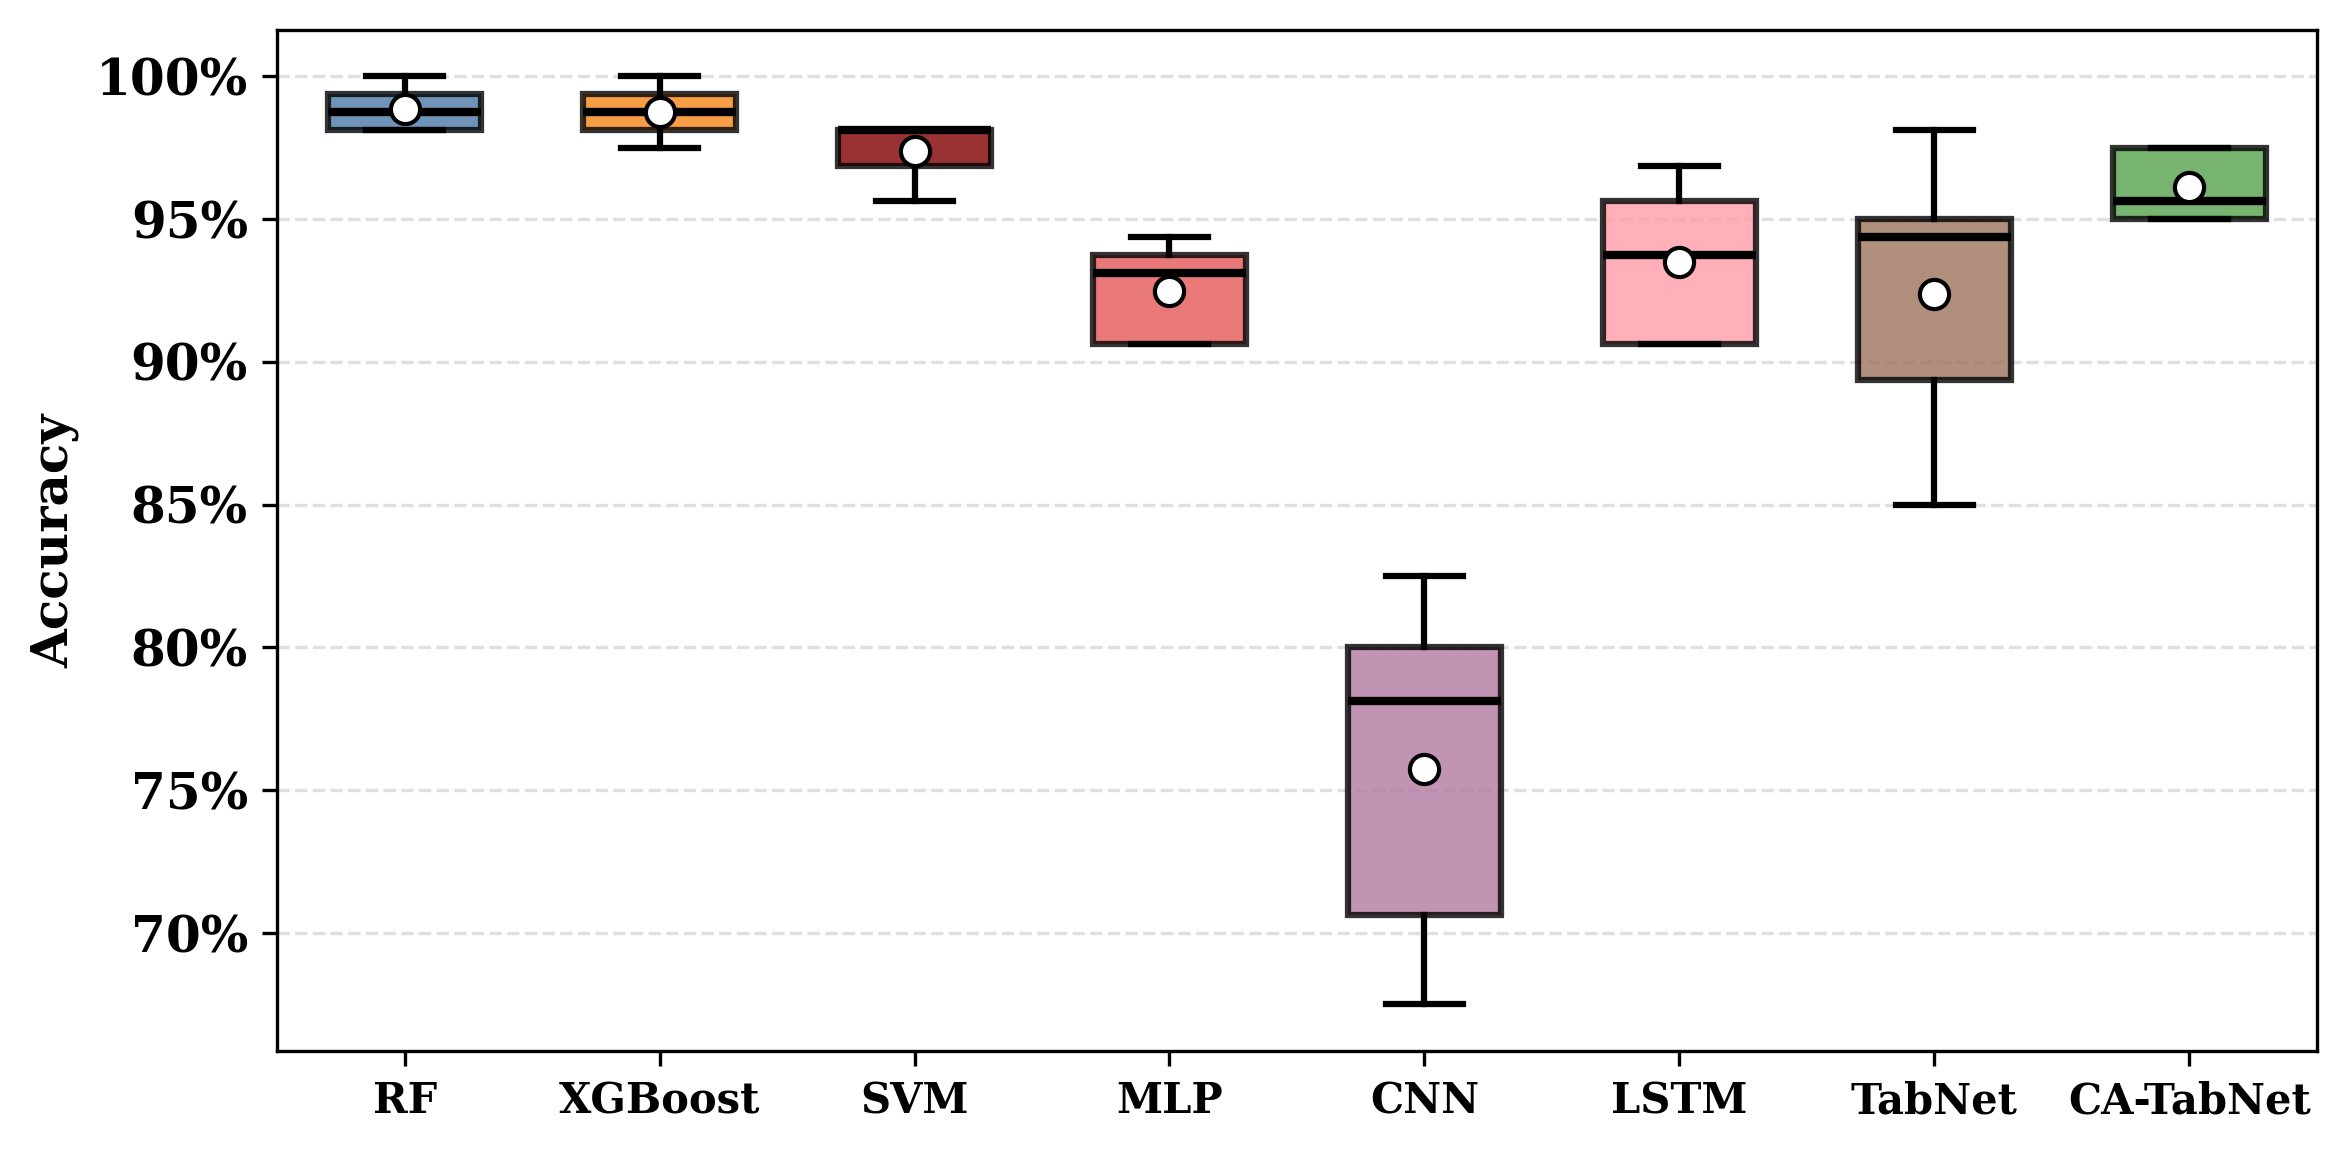

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import PercentFormatter

results_dir = Path("/content/drive/MyDrive/CA_TabNet_Results")

# Load saved results
old_df = pd.read_csv(results_dir / "All_Models_Foldwise.csv")

# Combine all eight models
fold_df = pd.concat([old_df], ignore_index=True)

labels = [
    "RF", "XGBoost", "SVM", "MLP",
    "CNN", "LSTM", "TabNet", "CA-TabNet"
]

data = [
    fold_df[fold_df["Model"] == model]
    .sort_values("Fold")["Accuracy"].to_numpy()
    for model in labels
]

# Verify five scores per model
assert all(len(scores) == 5 for scores in data)

fig, ax = plt.subplots(figsize=(8, 4), dpi=300)

box = ax.boxplot(
    data,
    patch_artist=True,
    widths=0.6,
    showmeans=True,
    meanline=False,
    medianprops=dict(color='black', linewidth=2),
    meanprops=dict(marker='o', markerfacecolor='white',
                   markeredgecolor='black', markersize=7),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    flierprops=dict(marker='o', markersize=5,
                    markerfacecolor='red', alpha=0.6)
)

colors = [
    '#4C78A8', '#F58518','#800000' , '#E45756',
    '#B279A2', '#FF9DA6', '#9D755D', '#54A24B'
]

for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.5)

ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels, fontsize=10, fontweight='bold')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_ylabel("Accuracy", fontsize=12, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.4)

for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')

plt.tight_layout()

plt.savefig(
    results_dir / "All_8_Models_Accuracy_Boxplot.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

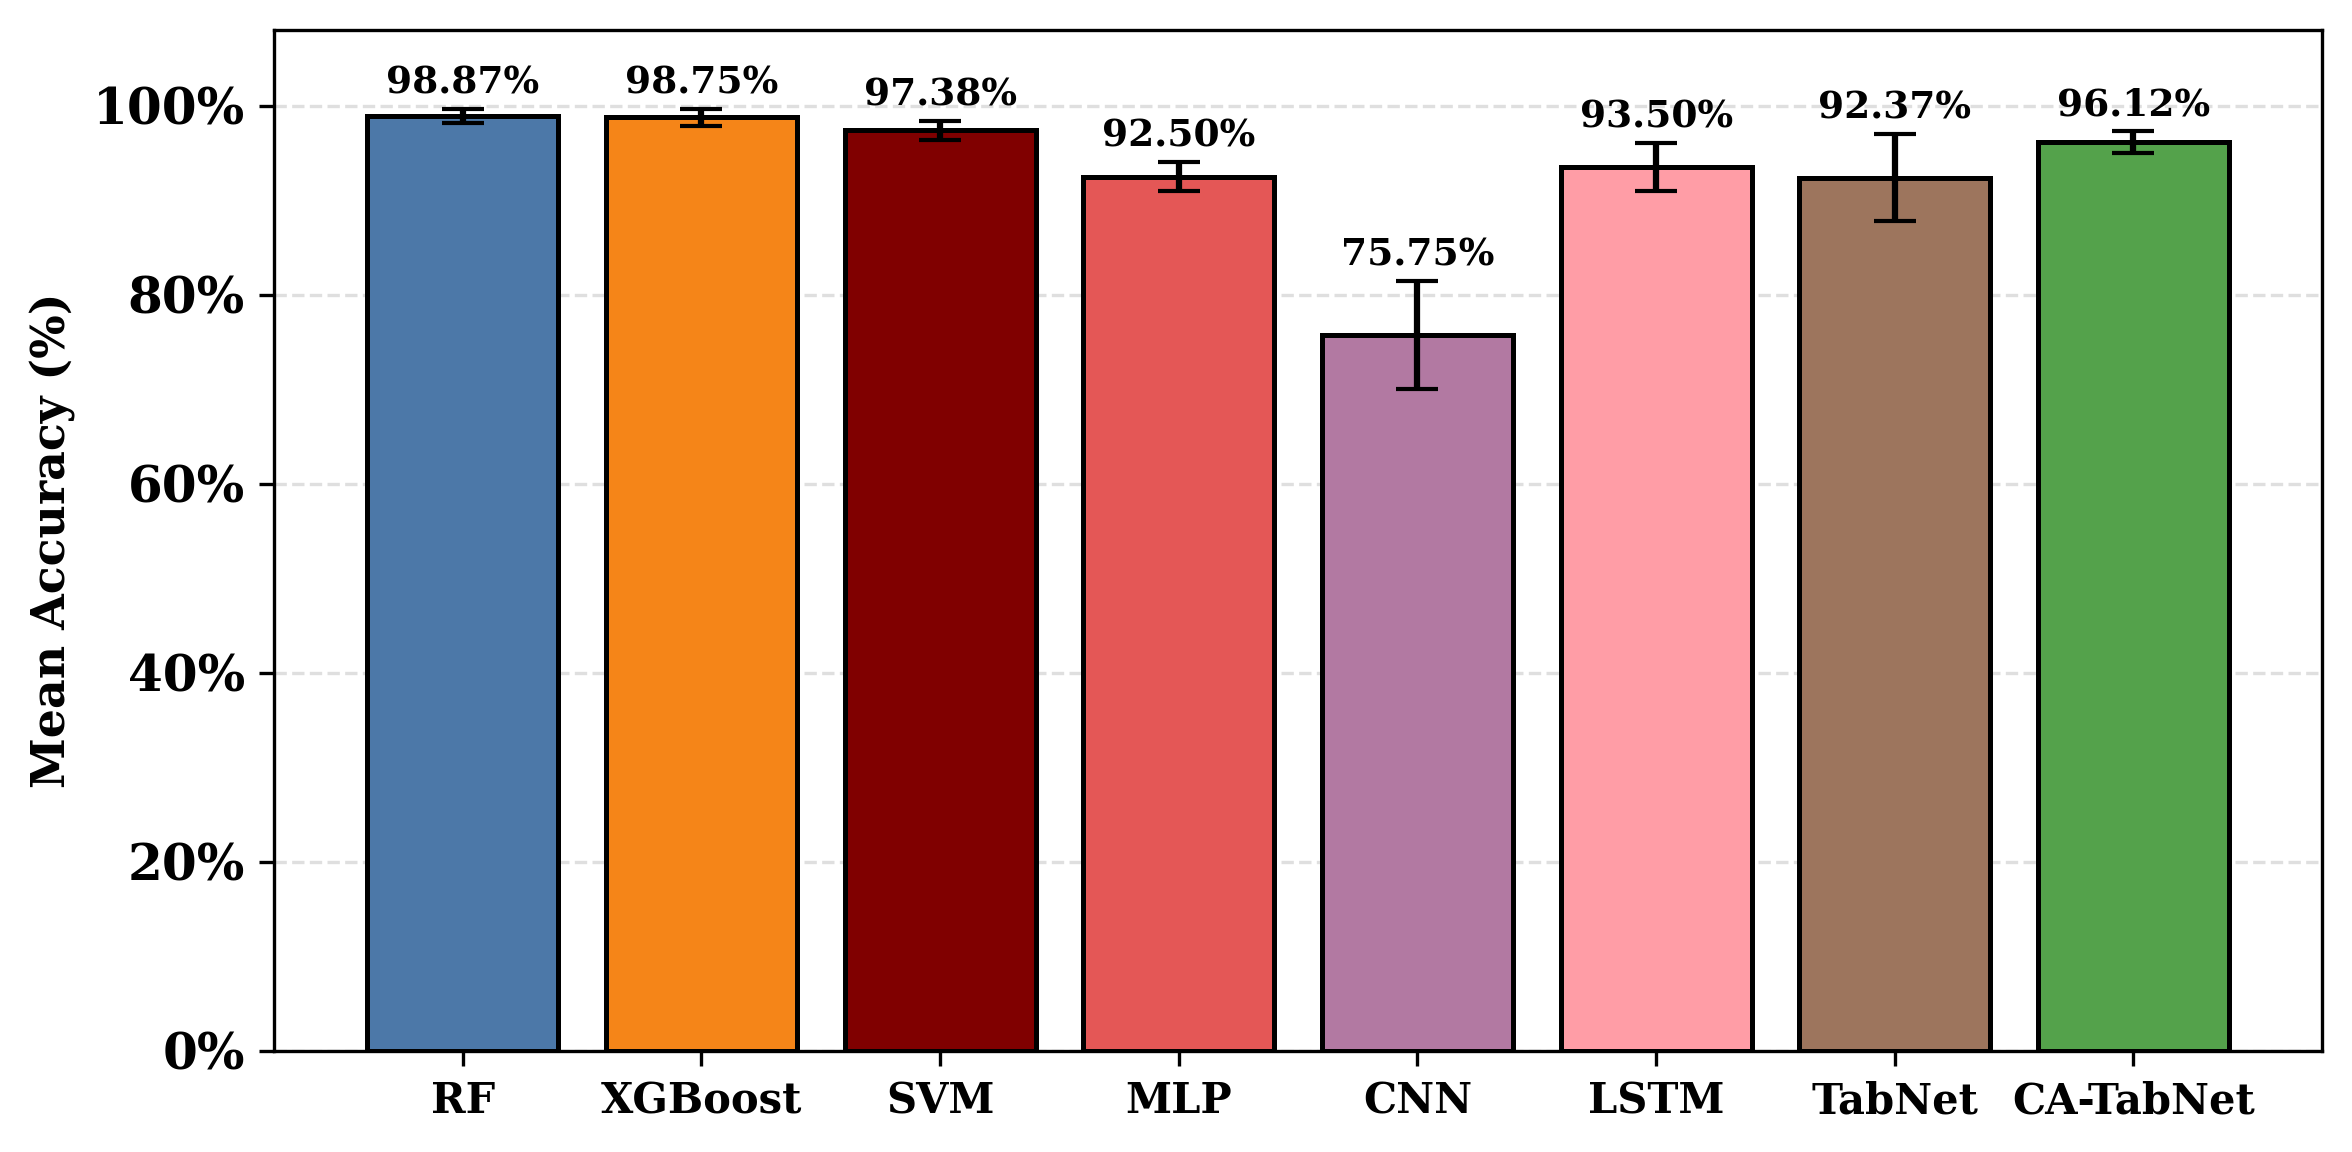

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import PercentFormatter

results_dir = Path("/content/drive/MyDrive/CA_TabNet_Results")

# Load all eight models
old_df = pd.read_csv(results_dir / "All_Models_Foldwise.csv")
fold_df = pd.concat([old_df], ignore_index=True)

labels = [
    "RF", "XGBoost", "SVM", "MLP",
    "CNN", "LSTM", "TabNet", "CA-TabNet"
]

scores_dict = {
    model: fold_df.loc[
        fold_df["Model"] == model, "Accuracy"
    ].to_numpy()
    for model in labels
}

assert all(len(scores_dict[k]) == 5 for k in labels)

means = [np.mean(scores_dict[k]) for k in labels]
stds = [np.std(scores_dict[k], ddof=0) for k in labels]

colors = [
    '#4C78A8', '#F58518', '#800000', '#E45756',
    '#B279A2', '#FF9DA6', '#9D755D', '#54A24B'
]

fig, ax = plt.subplots(figsize=(8, 4), dpi=300)

x = np.arange(len(labels))

bars = ax.bar(
    x,
    means,
    yerr=stds,
    capsize=5,
    edgecolor='black',
    linewidth=1.2,
    color=colors
)

# Display mean accuracy above each bar
for i, bar in enumerate(bars):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        means[i] + stds[i] + 0.008,
        f"{means[i]*100:.2f}%",
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10, fontweight='bold')

ax.set_ylabel("Mean Accuracy (%)", fontsize=11, fontweight='bold')

# Display accuracy as percentage
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

ax.set_ylim(0, 1.08)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')

plt.tight_layout()

plt.savefig(
    results_dir / "All_8_Models_Mean_Accuracy.png",
    dpi=600,
    bbox_inches='tight'
)


plt.show()

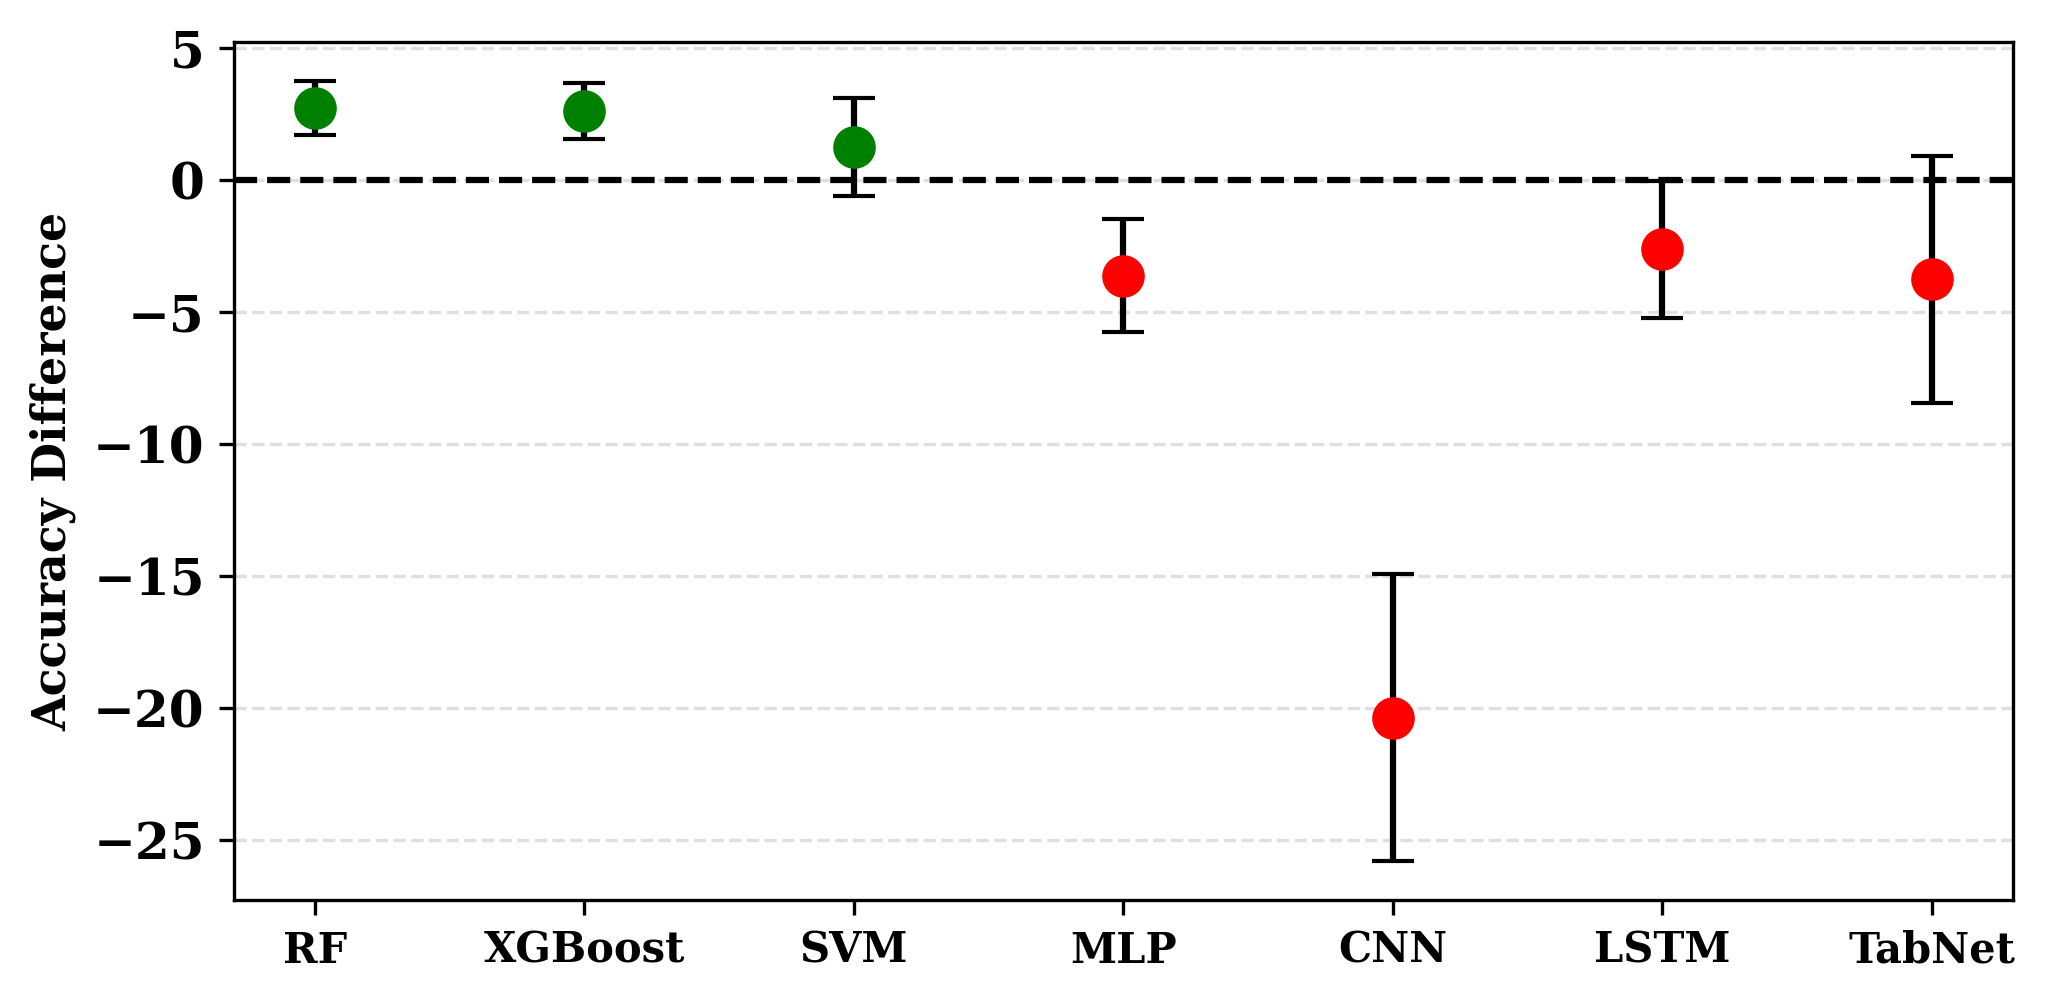

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

results_dir = Path("/content/drive/MyDrive/CA_TabNet_Results")

# Load all eight models
old_df = pd.read_csv(results_dir / "All_Models_Foldwise.csv")
df = pd.concat([old_df], ignore_index=True)

ref = "CA-TabNet"
baselines = ["RF", "XGBoost", "SVM", "MLP",
             "CNN", "LSTM", "TabNet"]

# Align accuracy values by CV fold
accuracy = df.pivot(index="Fold", columns="Model", values="Accuracy")

diff_means = []
diff_stds = []

for model in baselines:
    diff = (accuracy[model] - accuracy[ref]) * 100
    diff_means.append(diff.mean())
    diff_stds.append(diff.std(ddof=0))

x_pos = np.arange(len(baselines))
colors = ['green' if d > 0 else 'red' for d in diff_means]

fig, ax = plt.subplots(figsize=(7, 3.5), dpi=300)

ax.errorbar(
    x_pos, diff_means,
    yerr=diff_stds,
    fmt='none',
    ecolor='black',
    capsize=5,
    linewidth=1.5
)

for i, d in enumerate(diff_means):
    ax.scatter(x_pos[i], d, color=colors[i], s=85, zorder=3)

ax.axhline(0, color='black', linestyle='--', linewidth=1.5)

ax.set_xticks(x_pos)
ax.set_xticklabels(baselines, fontsize=10, fontweight='bold')

ax.set_ylabel("Accuracy Difference", fontsize=11,
              fontweight='bold')

ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')

plt.tight_layout()

plt.savefig(
    results_dir / "Accuracy_Difference_All_8_Models.png",
    dpi=600, bbox_inches="tight"
)
plt.show()


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import ttest_rel, t

results_dir = Path("/content/drive/MyDrive/CA_TabNet_Results")

# Load all eight models
old_df = pd.read_csv(results_dir / "All_Models_Foldwise.csv")

df = pd.concat([old_df], ignore_index=True)

accuracy = df.pivot(
    index="Fold",
    columns="Model",
    values="Accuracy"
)

reference = "CA-TabNet"
baselines = ["RF", "XGBoost", "SVM", "MLP",
             "CNN", "LSTM", "TabNet"]

results = []

for model in baselines:

    baseline_scores = accuracy[model].to_numpy()
    ca_scores = accuracy[reference].to_numpy()

    # Paired differences: baseline - CA-TabNet
    diff = baseline_scores - ca_scores

    n = len(diff)
    mean_diff = np.mean(diff)
    sd_diff = np.std(diff, ddof=1)
    se = sd_diff / np.sqrt(n)

    # Paired t-test
    t_stat, p_value = ttest_rel(
        baseline_scores, ca_scores
    )

    # 95% confidence interval
    t_critical = t.ppf(0.975, df=n-1)

    ci_lower = mean_diff - t_critical * se
    ci_upper = mean_diff + t_critical * se

    results.append({
        "Comparison": f"{model} vs. CA-TabNet",
        "Mean Difference": mean_diff,
        "95% CI": f"[{ci_lower:.4f}, {ci_upper:.4f}]",
        "t (df=4)": t_stat,
        "p-value": p_value,
        "Significant (α=0.05)": "Yes" if p_value < 0.05 else "No"
    })

stat_df = pd.DataFrame(results)

stat_df.to_csv(
    results_dir / "All_8_Models_Paired_TTests.csv",
    index=False
)

print(stat_df.round(4).to_string(index=False))

           Comparison  Mean Difference             95% CI  t (df=4)  p-value Significant (α=0.05)
     RF vs. CA-TabNet           0.0275   [0.0134, 0.0416]    5.4160   0.0056                  Yes
XGBoost vs. CA-TabNet           0.0263   [0.0113, 0.0412]    4.8824   0.0081                  Yes
    SVM vs. CA-TabNet           0.0125  [-0.0132, 0.0382]    1.3484   0.2488                   No
    MLP vs. CA-TabNet          -0.0362 [-0.0660, -0.0065]   -3.3826   0.0277                  Yes
    CNN vs. CA-TabNet          -0.2037 [-0.2791, -0.1284]   -7.5067   0.0017                  Yes
   LSTM vs. CA-TabNet          -0.0262  [-0.0624, 0.0099]   -2.0161   0.1140                   No
 TabNet vs. CA-TabNet          -0.0375  [-0.1024, 0.0274]   -1.6036   0.1841                   No


# Interpretability analysis

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import LabelEncoder, StandardScaler

df=pd.read_csv('Crop_recommendation.csv')
df.head()
X = df.drop('label', axis=1).values
y = df['label']

le = LabelEncoder()
y = le.fit_transform(y)

# Fixed CV splits

In [5]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

skf_all = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate identical folds for all models
cv_folds_all = list(skf_all.split(X, y))

# CA-Tabnet_ALL

In [9]:

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
from pytorch_tabnet.tab_model import TabNetClassifier

device = "cuda" if torch.cuda.is_available() else "cpu"

tabc_acc_scores_all = []
tabc_prec_scores_all = []
tabc_rec_scores_all = []
tabc_f1_scores_all = []
tabc_all_importances = []
for fold_no, (train_idx, test_idx) in enumerate(cv_folds_all, start=1):

    print(f"\n========== Fold {fold_no} ==========")

    torch.manual_seed(42 + fold_no)
    np.random.seed(42 + fold_no)

    # --------------------------------------------------
    # Outer training and independent test folds
    # --------------------------------------------------
    X_train_outer, X_test_fold = X[train_idx], X[test_idx]
    y_train_outer, y_test_fold = y[train_idx], y[test_idx]

    # --------------------------------------------------
    # Internal validation split for early stopping
    # --------------------------------------------------
    X_train_inner, X_val, y_train_inner, y_val = train_test_split(
        X_train_outer,
        y_train_outer,
        test_size=0.2,
        stratify=y_train_outer,
        random_state=42
    )

    # Scale using inner training data only
    scaler = StandardScaler()

    X_train_inner = scaler.fit_transform(
        X_train_inner
    ).astype(np.float32)

    X_val = scaler.transform(X_val).astype(np.float32)
    X_test_fold = scaler.transform(X_test_fold).astype(np.float32)

    # --------------------------------------------------
    # Stage 1: Train ContextClassifier
    # --------------------------------------------------
    ctxf_model = ContextClassifier(
        input_dim=X_train_inner.shape[1],
        num_classes=len(np.unique(y)),
        hidden_dim=8,
        alpha=0.3
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        ctxf_model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    X_train_t = torch.tensor(
        X_train_inner,
        dtype=torch.float32,
        device=device
    )

    y_train_t = torch.tensor(
        y_train_inner,
        dtype=torch.long,
        device=device
    )

    ctxf_model.train()

    for epoch in range(20):
        optimizer.zero_grad()

        logits, _, _ = ctxf_model(X_train_t)

        loss = criterion(logits, y_train_t)
        loss.backward()
        optimizer.step()

    # --------------------------------------------------
    # Stage 2: Generate context-transformed features
    # --------------------------------------------------
    ctxf_model.eval()

    def transform_context(X_data):
        with torch.no_grad():
            X_tensor = torch.tensor(
                X_data,
                dtype=torch.float32,
                device=device
            )

            X_ctx, _ = ctxf_model.gate(X_tensor)

        return X_ctx.detach().cpu().numpy().astype(np.float32)

    X_train_ctx = transform_context(X_train_inner)
    X_val_ctx = transform_context(X_val)
    X_test_ctx = transform_context(X_test_fold)

    # --------------------------------------------------
    # Stage 3: Train CA-TabNet
    # --------------------------------------------------
    tabnet_model3 = TabNetClassifier(
        n_d=8,
        n_a=32,
        n_steps=10,
        gamma=1.3,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=2e-2),
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        scheduler_params={
            "step_size": 10,
            "gamma": 0.9
        },
        mask_type="sparsemax",
        seed=42 + fold_no
    )

    tabnet_model3.fit(
        X_train_ctx,
        y_train_inner,
        eval_set=[(X_val_ctx, y_val)],
        eval_name=["valid"],
        eval_metric=["accuracy"],
        max_epochs=100,
        patience=20,
        batch_size=128,
        virtual_batch_size=32,
        num_workers=0,
        drop_last=False
    )

    # --------------------------------------------------
    # Stage 4: Independent test-fold evaluation
    # --------------------------------------------------
    all_importances.append(
    tabnet_model2.feature_importances_.copy()
    )

    y_pred = tabnet_model3.predict(X_test_ctx)

    acc = accuracy_score(y_test_fold, y_pred)

    prec = precision_score(
        y_test_fold,
        y_pred,
        average="weighted",
        zero_division=0
    )

    rec = recall_score(
        y_test_fold,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test_fold,
        y_pred,
        average="weighted",
        zero_division=0
    )

    tabc_acc_scores_all.append(acc)
    tabc_prec_scores_all.append(prec)
    tabc_rec_scores_all.append(rec)
    tabc_f1_scores_all.append(f1)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

# --------------------------------------------------
# Final summary
# --------------------------------------------------
print("\n===== CA-TabNet 5-Fold CV Results =====")

print(
    f"Accuracy : {np.mean(tabc_acc_scores_all):.4f} "
    f"± {np.std(tabc_acc_scores_all):.4f}"
)

print(
    f"Precision: {np.mean(tabc_prec_scores_all):.4f} "
    f"± {np.std(tabc_prec_scores_all):.4f}"
)

print(
    f"Recall   : {np.mean(tabc_rec_scores_all):.4f} "
    f"± {np.std(tabc_rec_scores_all):.4f}"
)

print(
    f"F1-score : {np.mean(tabc_f1_scores_all):.4f} "
    f"± {np.std(tabc_f1_scores_all):.4f}"
)



========== Fold 1 ==========


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 3.59066 | valid_accuracy: 0.22443 |  0:00:00s
epoch 1  | loss: 2.49346 | valid_accuracy: 0.24716 |  0:00:01s
epoch 2  | loss: 2.01265 | valid_accuracy: 0.55398 |  0:00:02s
epoch 3  | loss: 1.69944 | valid_accuracy: 0.55114 |  0:00:02s
epoch 4  | loss: 1.63465 | valid_accuracy: 0.48011 |  0:00:03s
epoch 5  | loss: 1.43494 | valid_accuracy: 0.62216 |  0:00:04s
epoch 6  | loss: 1.2074  | valid_accuracy: 0.62216 |  0:00:05s
epoch 7  | loss: 0.97778 | valid_accuracy: 0.65625 |  0:00:05s
epoch 8  | loss: 0.93085 | valid_accuracy: 0.70739 |  0:00:06s
epoch 9  | loss: 0.89358 | valid_accuracy: 0.66477 |  0:00:08s
epoch 10 | loss: 0.8464  | valid_accuracy: 0.7358  |  0:00:09s
epoch 11 | loss: 0.72827 | valid_accuracy: 0.82955 |  0:00:10s
epoch 12 | loss: 0.65145 | valid_accuracy: 0.84943 |  0:00:11s
epoch 13 | loss: 0.62689 | valid_accuracy: 0.85511 |  0:00:13s
epoch 14 | loss: 0.58083 | valid_accuracy: 0.84659 |  0:00:15s
epoch 15 | loss: 0.67367 | valid_accuracy: 0.88352 |  0

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Accuracy : 0.9818
Precision: 0.9837
Recall   : 0.9818
F1-score : 0.9817

========== Fold 2 ==========


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


... (11 outputs left out)

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 4.05844 | valid_accuracy: 0.1733  |  0:00:00s
epoch 1  | loss: 2.41281 | valid_accuracy: 0.39205 |  0:00:01s
epoch 2  | loss: 1.92273 | valid_accuracy: 0.4517  |  0:00:02s
epoch 3  | loss: 1.72719 | valid_accuracy: 0.55682 |  0:00:03s
epoch 4  | loss: 1.54492 | valid_accuracy: 0.5625  |  0:00:04s
epoch 5  | loss: 1.47044 | valid_accuracy: 0.59375 |  0:00:05s
epoch 6  | loss: 1.3956  | valid_accuracy: 0.61364 |  0:00:06s
epoch 7  | loss: 1.02915 | valid_accuracy: 0.77557 |  0:00:07s
epoch 8  | loss: 0.9439  | valid_accuracy: 0.76705 |  0:00:08s
epoch 9  | loss: 0.8333  | valid_accuracy: 0.79261 |  0:00:09s
epoch 10 | loss: 1.06287 | valid_accuracy: 0.72443 |  0:00:10s
epoch 11 | loss: 0.72586 | valid_accuracy: 0.83807 |  0:00:11s
epoch 12 | loss: 0.65079 | valid_accuracy: 0.84375 |  0:00:12s
epoch 13 | loss: 0.58017 | valid_accuracy: 0.85795 |  0:00:12s
epoch 14 | loss: 0.48658 | valid_accuracy: 0.89205 |  0:00:13s
epoch 15 | loss: 0.45909 | valid_accuracy: 0.90909 |  0

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Accuracy : 0.9886
Precision: 0.9890
Recall   : 0.9886
F1-score : 0.9886

===== CA-TabNet 5-Fold CV Results =====
Accuracy : 0.9782 ± 0.0082
Precision: 0.9801 ± 0.0084
Recall   : 0.9782 ± 0.0082
F1-score : 0.9780 ± 0.0083


# Feature Importance Analysis

# Global

In [11]:
feature_names = ["N", "P", "K", "pH", "T", "H", "R"]

importance = tabnet_model3.feature_importances_

for name, value in sorted(
    zip(feature_names, importance),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{name}: {value:.6f}")

R: 0.197440
N: 0.195280
T: 0.170772
P: 0.166942
K: 0.109419
pH: 0.093241
H: 0.066907


In [ ]:
mean_importance = np.mean(all_importances, axis=0)

for name, value in zip(feature_names, mean_importance):
    print(f"{name}: {value:.6f}")

# Intrinsic Decision-Step Feature Analysis

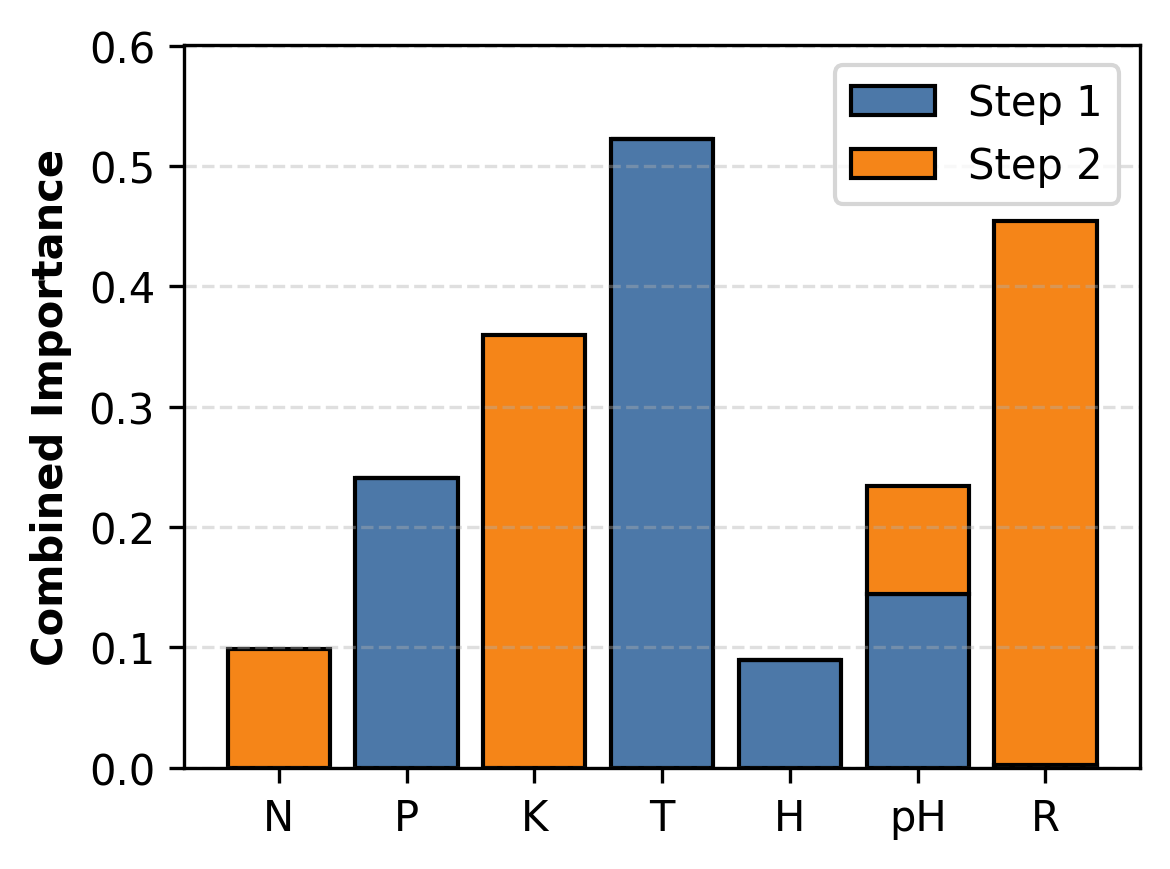

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# -----------------------------------
# 1. Recover original test fold
# -----------------------------------
feature_names = ['N', 'P', 'K', 'T', 'H', 'pH', 'R']

X_test_original = X[test_idx]

# -----------------------------------
# 2. Apply trained scaler
# -----------------------------------
X_test_scaled_original = scaler.transform(
    X_test_original
).astype(np.float32)

# -----------------------------------
# 3. Apply trained context gate
# -----------------------------------
ctxf_model.eval()

with torch.no_grad():
    X_tensor_original = torch.tensor(
        X_test_scaled_original,
        dtype=torch.float32,
        device=device
    )

    X_test_ctx_original, _ = ctxf_model.gate(X_tensor_original)

    X_test_ctx_original = (
        X_test_ctx_original.cpu().numpy().astype(np.float32)
    )

# -----------------------------------
# 4. Extract decision-step masks
# -----------------------------------
_, masks_original = tabnet_model3.explain(
    X_test_ctx_original,
    normalize=False
)

step1_original = masks_original[7].mean(axis=0)
step2_original = masks_original[8].mean(axis=0)

# Normalize each step
step1_original = step1_original / step1_original.sum()
step2_original = step2_original / step2_original.sum()

# -----------------------------------
# 5. Original stacked bar plot
# -----------------------------------
x = np.arange(len(feature_names))

plt.figure(figsize=(4, 3), dpi=300)

plt.bar(
    x,
    step1_original,
    label='Step 1',
    color='#4C78A8',
    edgecolor='black'
)

plt.bar(
    x,
    step2_original,
    bottom=step1_original,
    label='Step 2',
    color='#F58518',
    edgecolor='black'
)

plt.xticks(x, feature_names)
plt.ylabel("Combined Importance", fontsize=10,fontweight='bold')
plt.ylim(0, max(step1_original + step2_original)*1.15 )
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# SHAP Analysis

In [61]:
!pip install -q shap lime

# Summary Plot

In [66]:
import shap
import lime.lime_tabular
import matplotlib.pyplot as plt

from pathlib import Path

save_dir = Path("/content/drive/MyDrive/CA_TabNet_Results")
save_dir.mkdir(parents=True, exist_ok=True)

feature_names = ["N", "P", "K", "pH", "T", "H", "R"]

ctxf_model.eval()

def predict_ca_tabnet(data):
    data = np.asarray(data, dtype=np.float32)

    with torch.no_grad():
        x = torch.tensor(data, dtype=torch.float32, device=device)
        x_ctx, _ = ctxf_model.gate(x)

    return tabnet_model3.predict_proba(
        x_ctx.cpu().numpy().astype(np.float32)
    )

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt


feature_names = ["N", "P", "K", "pH", "T", "H", "R"]

# 1. Select 200 test samples
rng = np.random.default_rng(42)
idx = rng.choice(
    len(X_test_fold),
    size=min(200, len(X_test_fold)),
    replace=False
)

X_explain = X_test_fold[idx]

# 2. Select 50 training samples as background
background = shap.sample(
    X_train_inner, 50, random_state=42
)

# 3. SHAP explainer for the complete CA-TabNet model
explainer = shap.KernelExplainer(
    predict_ca_tabnet,
    background
)

shap_values = explainer.shap_values(
    X_explain,
    nsamples=100
)

# 4. Handle SHAP output: (samples, features, classes)
if isinstance(shap_values, list):
    shap_array = np.stack(shap_values, axis=-1)
else:
    shap_array = np.asarray(shap_values)

# 5. Extract SHAP values for each sample's predicted class
probs_explain = predict_ca_tabnet(X_explain)
pred_positions = np.argmax(probs_explain, axis=1)

shap_global = shap_array[
    np.arange(len(X_explain)),
    :,
    pred_positions
]

# 6. Convert values to original agricultural units
X_original = scaler.inverse_transform(X_explain)

# 7. Generate global SHAP beeswarm plot
plt.close("all")





In [67]:
# 8. Global feature importance
importance = np.mean(np.abs(shap_global), axis=0)

print("\nGlobal SHAP Feature Importance")
for i in np.argsort(importance)[::-1]:
    print(f"{feature_names[i]:<5}: {importance[i]:.6f}")


Global SHAP Feature Importance
T    : 0.235479
K    : 0.173058
N    : 0.162167
R    : 0.159403
P    : 0.142169
pH   : 0.046170
H    : 0.022431


/tmp/ipykernel_911/1993133538.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


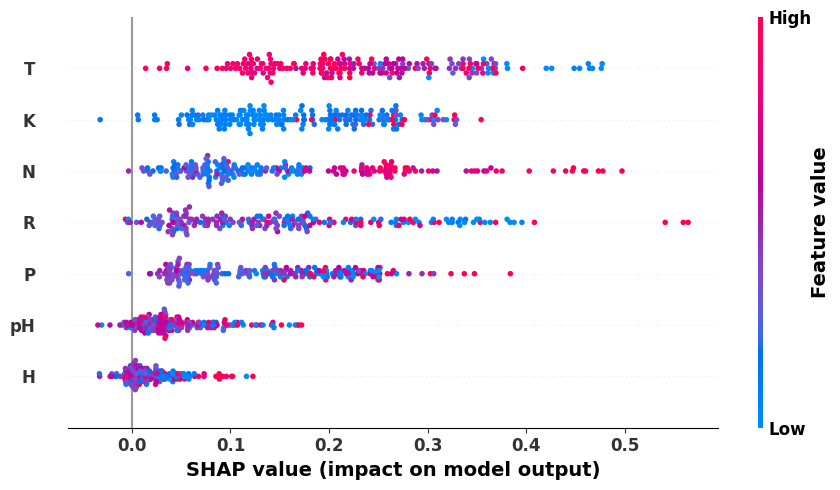

In [72]:
import shap
import numpy as np
import matplotlib.pyplot as plt

plt.close("all")

shap.summary_plot(
    shap_global,
    X_original,
    feature_names=feature_names,
    plot_type="dot",
    max_display=7,
    show=False
)

fig = plt.gcf()
fig.set_size_inches(9, 5)

# Main axis
ax = plt.gca()
ax.set_xlabel("SHAP value (impact on model output)",
              fontsize=14, fontweight="bold")
ax.set_ylabel("",
              fontsize=14, fontweight="bold")   # no y-axis title in SHAP beeswarm

# Make x tick labels bold
for tick in ax.get_xticklabels():
    tick.set_fontsize(12)
    tick.set_fontweight("bold")

# Make y tick labels bold
for tick in ax.get_yticklabels():
    tick.set_fontsize(12)
    tick.set_fontweight("bold")

# Colorbar axis is usually the second axis
if len(fig.axes) > 1:
    cbar_ax = fig.axes[-1]
    cbar_ax.set_ylabel("Feature value",
                       fontsize=14, fontweight="bold")

    for tick in cbar_ax.get_yticklabels():
        tick.set_fontsize(12)
        tick.set_fontweight("bold")

if len(fig.axes) > 1:
    cbar_ax = fig.axes[-1]
    for txt in cbar_ax.texts:
        txt.set_fontweight("bold")
        txt.set_fontsize(12)
plt.tight_layout()

fig.savefig(
    save_dir / "CA_TabNet_Global_SHAP.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# Local

In [69]:
# Identify pigeonpeas class from your original crop labels.
# Replace 'pigeonpeas' with its encoded class ID if needed.
pigeonpeas_id = int(le.transform(["pigeonpeas"])[0])

probs = predict_ca_tabnet(X_test_fold)
classes = np.asarray(tabnet_model3.classes_)

predicted = classes[np.argmax(probs, axis=1)]

# Choose a correctly predicted pigeonpeas sample
candidates = np.where(
    (predicted == pigeonpeas_id) &
    (y_test_fold == pigeonpeas_id)
)[0]

sample_idx = int(candidates[3])
x_sample = X_test_fold[sample_idx]

class_idx = int(np.where(classes == pigeonpeas_id)[0][0])

print("Sample:", sample_idx)
print("Pigeonpeas probability:", probs[sample_idx, class_idx])

Sample: 83
Pigeonpeas probability: 0.95976496


In [77]:
sample_idx = 83

X_lime_sample = X_test_fold[sample_idx:sample_idx+1]

# Find the crop class predicted for this specific sample
probs = predict_ca_tabnet(X_lime_sample)
class_idx = np.argmax(probs[0])

# Calculate SHAP values for this exact input
shap_one = explainer.shap_values(X_lime_sample, nsamples=100)

if isinstance(shap_one, list):
    shap_one = np.stack(shap_one, axis=-1)

sample_shap = shap_one[0, :, class_idx]
base_value = np.asarray(explainer.expected_value)[class_idx]


  0%|          | 0/1 [00:00<?, ?it/s]

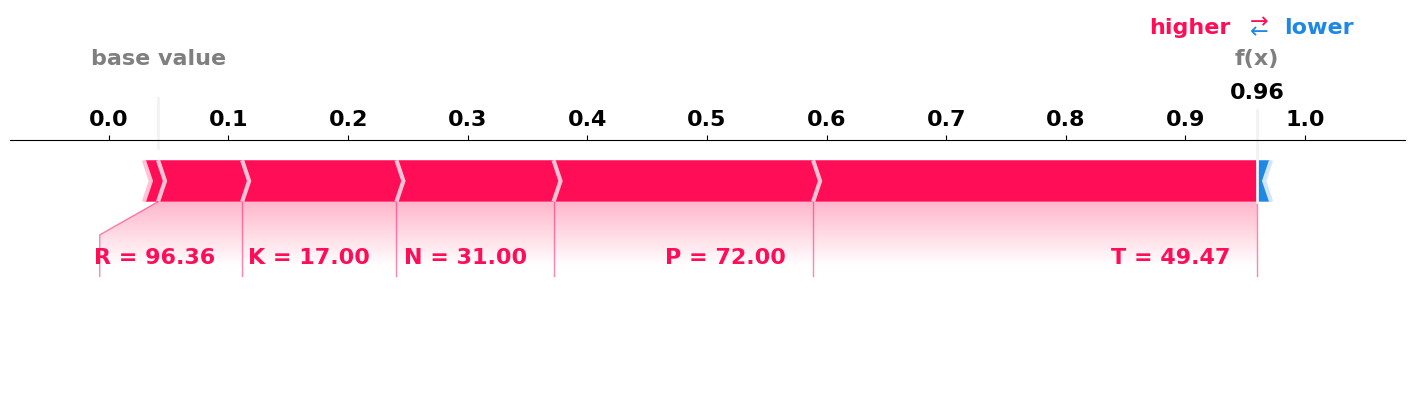

In [78]:
import numpy as np
import matplotlib.pyplot as plt
import shap

shap.initjs()

# Convert standardized values to original agricultural values
x_original = scaler.inverse_transform(
    x_sample.reshape(1, -1)
)[0]

# Display values with two decimal places
feature_labels = [
    f"{name} = {value:.2f}"
    for name, value in zip(short_names, x_original)
]

plt.close("all")

# SHAP force plot
shap.force_plot(
    base_value,
    sample_shap,
    features=feature_labels,
    matplotlib=True,
    show=False,
    figsize=(18, 3.5)
)

# Customize font size and boldness
fig = plt.gcf()

for txt in fig.findobj(match=plt.Text):
    txt.set_fontweight("bold")
    txt.set_fontsize(16)

plt.xticks(fontsize=16, fontweight="bold")

# Save high-resolution figures
fig.savefig(
    save_dir / "SHAP_Local_Force.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.3
)

plt.show()

# Lime Analysis

In [79]:
import lime.lime_tabular
from lime.lime_tabular import LimeTabularExplainer

feature_names = ["N", "P", "K", "pH", "T", "H", "R"]

# Convert standardized values to original values
X_train_original = scaler.inverse_transform(X_train_inner)
x_original = scaler.inverse_transform(
    x_sample.reshape(1, -1)
)[0]

# Prediction function accepting original feature values
def predict_lime(data):
    data_scaled = scaler.transform(
        np.asarray(data, dtype=np.float32)
    ).astype(np.float32)
    return predict_ca_tabnet(data_scaled)

explainer = LimeTabularExplainer(
    training_data=X_train_original,
    feature_names=feature_names,
    class_names=list(le.inverse_transform(classes.astype(int))),
    mode="classification",
    random_state=42
)

exp1 = explainer.explain_instance(
    x_original,
    predict_lime,
    num_features=7,
    labels=[class_idx],
    num_samples=5000
)

exp1.show_in_notebook()

In [80]:
from IPython.display import HTML, display

# Generate the HTML output instead of show_in_notebook()
lime_html = exp1.as_html()

# Custom CSS overrides
css = """
<style>

.lime * {
    font-family: Arial, sans-serif !important;
}

/* GLOBAL FONT FIX */
.lime {
    font-size: 30px !important;
}

/* SCALE THE ENTIRE VISUALIZATION */
.lime {
    transform: scale(1.05);
    transform-origin: top left;
}

/* FIX SVG LABELS */
.lime svg text {
    font-size: 14px !important;
    fill: #003366 !important;
    font-weight: 600 !important;
}
.lime b,
.lime strong {
    font-size: 30px !important;
    color: #003366 !important;
    font-weight: 800 !important;
}
/* FIX PROBABILITY BARS (left side) */
.lime .lime-top-label,
.lime .lime-label {
    font-size: 30px !important;
    font-weight: 700 !important;
    color: #003366 !important;
}

/* Make numbers bigger and aligned */
.lime td {
    font-size: 16px !important;
    font-weight: 600 !important;
}

/* Feature-value table (right side) */
.lime table {
    border-collapse: collapse !important;
}

.lime table td {
    padding: 6px 10px !important;
}
.lime *:contains("Prediction probabilities"),
.lime *:contains("NOT"),
.lime *:contains("pigeonpeas") {
    font-size: 28px !important;
    font-weight: 800 !important;
    color: #003366 !important;
}

</style>
"""


# Combine CSS + LIME output
styled_html = css + lime_html

# Display
display(HTML(styled_html))


# Deployment analysis

In [81]:
import copy
import io
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.utils.prune as prune

from sklearn.metrics import accuracy_score

# --------------------------------------------
# 1. Preserve original trained models
# --------------------------------------------
ctx_original = ctxf_model
tab_original = tabnet_model3

# Create independent copies for pruning
ctx_pruned = copy.deepcopy(ctx_original)
tab_pruned = copy.deepcopy(tab_original)

ctx_original.eval()
ctx_pruned.eval()

tab_original.network.eval()
tab_pruned.network.eval()

# --------------------------------------------
# 2. Apply 20% global L1 pruning
# --------------------------------------------
layers = []

# Context gate
for module in ctx_pruned.gate.modules():
    if isinstance(module, nn.Linear):
        layers.append((module, "weight"))

# TabNet classifier
for module in tab_pruned.network.modules():
    if isinstance(module, nn.Linear):
        layers.append((module, "weight"))

print("Linear layers selected:", len(layers))

if not layers:
    raise ValueError("No linear layers found for pruning.")

prune.global_unstructured(
    layers,
    pruning_method=prune.L1Unstructured,
    amount=0.20
)

# Make pruning permanent
for module, parameter in layers:
    prune.remove(module, parameter)

# --------------------------------------------
# 3. Prepare original test fold
# --------------------------------------------
X_test_raw = X[test_idx]
y_test = y[test_idx]

X_test_scaled = scaler.transform(
    X_test_raw
).astype(np.float32)

# --------------------------------------------
# 4. Complete CA-TabNet prediction
# --------------------------------------------
def predict_pipeline(ctx_model, tab_model, X_input):

    ctx_model.eval()

    model_device = next(
        ctx_model.parameters()
    ).device

    with torch.no_grad():
        X_tensor = torch.as_tensor(
            X_input,
            dtype=torch.float32,
            device=model_device
        )

        X_context, _ = ctx_model.gate(X_tensor)

        X_context = (
            X_context.cpu().numpy().astype(np.float32)
        )

    return tab_model.predict(X_context)


# --------------------------------------------
# 5. Accuracy comparison
# --------------------------------------------
pred_original = predict_pipeline(
    ctx_original, tab_original, X_test_scaled
)

pred_pruned = predict_pipeline(
    ctx_pruned, tab_pruned, X_test_scaled
)

acc_original = accuracy_score(y_test, pred_original) * 100
acc_pruned = accuracy_score(y_test, pred_pruned) * 100

agreement = np.mean(pred_original == pred_pruned) * 100

# --------------------------------------------
# 6. Count zero-valued linear weights
# --------------------------------------------
def weight_sparsity(ctx_model, tab_model):

    weights = []

    for network in [ctx_model.gate, tab_model.network]:
        for module in network.modules():
            if isinstance(module, nn.Linear):
                weights.append(module.weight.detach())

    total = sum(w.numel() for w in weights)

    zeros = sum(
        torch.count_nonzero(w == 0).item()
        for w in weights
    )

    return 100 * zeros / total


# --------------------------------------------
# 7. Serialized model size
# --------------------------------------------
def model_size_mb(ctx_model, tab_model):

    buffer = io.BytesIO()

    torch.save(
        {
            "context_gate": ctx_model.gate.state_dict(),
            "tabnet": tab_model.network.state_dict()
        },
        buffer
    )

    return len(buffer.getvalue()) / (1024 ** 2)


# --------------------------------------------
# 8. Measure inference latency
# --------------------------------------------
def measure_latency(ctx_model, tab_model, X_input):

    # Same single sample for both models
    sample = X_input[:1]

    # Warm-up
    for _ in range(10):
        predict_pipeline(ctx_model, tab_model, sample)

    times = []

    for _ in range(100):
        start = time.perf_counter()

        predict_pipeline(ctx_model, tab_model, sample)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        times.append(
            (time.perf_counter() - start) * 1000
        )

    return np.mean(times), np.std(times)


lat_original = measure_latency(
    ctx_original, tab_original, X_test_scaled
)

lat_pruned = measure_latency(
    ctx_pruned, tab_pruned, X_test_scaled
)

# --------------------------------------------
# 9. Final comparison
# --------------------------------------------
results = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Zero weights (%)",
        "Model size (MB)",
        "Inference latency (ms)"
    ],
    "Original CA-TabNet": [
        round(acc_original, 4),
        round(weight_sparsity(ctx_original, tab_original), 2),
        round(model_size_mb(ctx_original, tab_original), 4),
        f"{lat_original[0]:.3f} ± {lat_original[1]:.3f}"
    ],
    "Pruned CA-TabNet": [
        round(acc_pruned, 4),
        round(weight_sparsity(ctx_pruned, tab_pruned), 2),
        round(model_size_mb(ctx_pruned, tab_pruned), 4),
        f"{lat_pruned[0]:.3f} ± {lat_pruned[1]:.3f}"
    ]
})

print(results.to_string(index=False))

print(f"\nPrediction agreement: {agreement:.2f}%")

Linear layers selected: 37
                Metric Original CA-TabNet Pruned CA-TabNet
          Accuracy (%)            98.8636          97.9545
      Zero weights (%)                0.0             20.0
       Model size (MB)             0.4783           0.4783
Inference latency (ms)    80.391 ± 39.786  66.267 ± 29.433

Prediction agreement: 98.18%


In [82]:
from pathlib import Path
import torch
import numpy as np
import joblib

# Output directory
save_dir = Path("/content/CA_TabNet_Compressed")
save_dir.mkdir(parents=True, exist_ok=True)

# Save the pruned models
checkpoint = {
    "context_gate_state_dict": ctx_pruned.gate.state_dict(),
    "tabnet_state_dict": tab_pruned.network.state_dict(),

    "input_dim": 7,
    "num_classes": len(np.unique(y)),
    "hidden_dim": 8,
    "alpha": 0.3,

    "tabnet_params": {
        "n_d": tab_pruned.n_d,
        "n_a": tab_pruned.n_a,
        "n_steps": tab_pruned.n_steps,
        "gamma": tab_pruned.gamma,
        "mask_type": tab_pruned.mask_type
    },

    "pruning_ratio": 0.20,
    "precision": "FP32",

    "feature_names": [
        "N", "P", "K", "temperature",
        "humidity", "ph", "rainfall"
    ],

    "classes": np.asarray(tab_pruned.classes_).tolist()
}

torch.save(
    checkpoint,
    save_dir / "CA_TabNet_Pruned_20pct.pth"
)

# Save preprocessing scaler
joblib.dump(
    scaler,
    save_dir / "scaler.pkl"
)

print("Saved files:")
print(save_dir / "CA_TabNet_Pruned_20pct.pth")
print(save_dir / "scaler.pkl")

Saved files:
/content/CA_TabNet_Compressed/CA_TabNet_Pruned_20pct.pth
/content/CA_TabNet_Compressed/scaler.pkl


In [83]:
# Save the scaled test data after context gating
ctx_pruned.eval()

with torch.no_grad():
    X_tensor = torch.tensor(
        X_test_scaled,
        dtype=torch.float32,
        device=next(ctx_pruned.parameters()).device
    )

    X_ctx_pruned, _ = ctx_pruned.gate(X_tensor)

    X_ctx_pruned = X_ctx_pruned.cpu().numpy().astype(np.float32)

reference_probabilities = tab_pruned.predict_proba(X_ctx_pruned)
reference_predictions = tab_pruned.predict(X_ctx_pruned)

np.savez_compressed(
    save_dir / "pruned_reference.npz",
    X_test_scaled=X_test_scaled,
    probabilities=reference_probabilities,
    predictions=reference_predictions,
    y_test=y_test
)

print("Reference predictions saved.")

Reference predictions saved.


In [84]:
!pip -q install onnx onnxruntime
import copy, numpy as np, torch, torch.nn as nn, onnxruntime as ort

onnx_path = save_dir / "CA_TabNet_Pruned_20pct.onnx"

# 1. ONNX-compatible sparsemax (pytorch-tabnet's own version cannot be exported)
class PlainSparsemax(nn.Module):
    def forward(self, z):
        zs, _ = torch.sort(z, dim=-1, descending=True)
        k = torch.arange(1, z.size(-1) + 1, dtype=z.dtype)
        cssv = zs.cumsum(-1) - 1
        k_z = ((k * zs) > cssv).sum(-1, keepdim=True).clamp(min=1)
        tau = cssv.gather(-1, k_z - 1) / k_z.to(z.dtype)
        return torch.clamp(z - tau, min=0.0)

# 2. Full pruned CA-TabNet: scaled input -> context gate -> TabNet -> probabilities
class CATabNetONNX(nn.Module):
    def __init__(self, gate, tabnet):
        super().__init__(); self.gate, self.tabnet = gate, tabnet
    def forward(self, x):
        x_ctx, _ = self.gate(x)
        logits, _ = self.tabnet(x_ctx)
        return torch.softmax(logits, dim=-1)

gate = copy.deepcopy(ctx_pruned.gate).cpu().eval()
tabnet = copy.deepcopy(tab_pruned.network).cpu().eval()
for m in tabnet.modules():
    if type(getattr(m, "selector", None)).__name__ == "Sparsemax":
        m.selector = PlainSparsemax()
model = CATabNetONNX(gate, tabnet).eval()

# 3. Export
torch.onnx.export(model, torch.zeros(1, 7), str(onnx_path),
                  input_names=["features"], output_names=["probabilities"],
                  dynamic_axes={"features": {0: "batch"}, "probabilities": {0: "batch"}},
                  opset_version=17, dynamo=False)
print("Saved:", onnx_path, f"({onnx_path.stat().st_size/1024:.1f} KB)")

# 4. Check accuracy of the ONNX file
X_chk = X_test_scaled.astype(np.float32)
sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
onnx_proba = sess.run(None, {"features": X_chk})[0]
onnx_pred = onnx_proba.argmax(1)

with torch.no_grad():                                   # the pruned PyTorch model, for comparison
    Xg, _ = ctx_pruned.gate(torch.tensor(X_chk, device=next(ctx_pruned.parameters()).device))
torch_proba = tab_pruned.predict_proba(Xg.cpu().numpy().astype(np.float32))
torch_pred = torch_proba.argmax(1)

print(f"PyTorch pruned accuracy : {100*(torch_pred == y_test).mean():.2f}%")
print(f"ONNX pruned accuracy    : {100*(onnx_pred == y_test).mean():.2f}%")
print(f"ONNX vs PyTorch agreement: {100*(onnx_pred == torch_pred).mean():.2f}%")
print(f"Max probability difference: {np.abs(onnx_proba - torch_proba).max():.2e}")

/tmp/ipykernel_911/24342189.py:33: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, torch.zeros(1, 7), str(onnx_path),
/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/tab_network.py:35: TracerWarning: Converting a tensor to a Python integer might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  chunks = x.chunk(int(np.ceil(x.shape[0] / self.virtual_batch_size)), 0)


Saved: /content/CA_TabNet_Compressed/CA_TabNet_Pruned_20pct.onnx (881.3 KB)
PyTorch pruned accuracy : 97.95%
ONNX pruned accuracy    : 97.95%
ONNX vs PyTorch agreement: 100.00%
Max probability difference: 1.78e-04


In [85]:
import time, platform, subprocess
import numpy as np, onnxruntime as ort

def cpu_latency(model_path, X, warmup=50):
    so = ort.SessionOptions()
    so.intra_op_num_threads = 1                  # single thread, comparable to a phone core
    so.inter_op_num_threads = 1
    s = ort.InferenceSession(str(model_path), so, providers=["CPUExecutionProvider"])
    name = s.get_inputs()[0].name
    for i in range(warmup):                      # warm-up runs (not timed)
        s.run(None, {name: X[i % len(X):i % len(X) + 1]})
    t = []
    for i in range(len(X)):                      # one sample per call
        t0 = time.perf_counter()
        s.run(None, {name: X[i:i + 1]})
        t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    return t.mean(), t.std(), np.median(t), np.percentile(t, 95)

X_lat = X_test_scaled.astype(np.float32)
models = {
    "Original CA-TabNet (FP32)": "/content/drive/MyDrive/CA_TabNet_Android_22Crops/CA_TabNet_22Crops_FP32.onnx",
    "Pruned CA-TabNet (20%)":    str(onnx_path),
}
print(subprocess.run("lscpu | grep 'Model name'", shell=True, capture_output=True, text=True).stdout.strip())
print(f"Samples timed: {len(X_lat)} (single-sample inference, 1 thread)\n")
for name, path in models.items():
    m, sd, med, p95 = cpu_latency(path, X_lat)
    print(f"{name:28s} mean {m:.3f} ± {sd:.3f} ms | median {med:.3f} ms | p95 {p95:.3f} ms")

Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
Samples timed: 440 (single-sample inference, 1 thread)

Original CA-TabNet (FP32)    mean 8.558 ± 5.095 ms | median 7.447 ms | p95 17.830 ms
Pruned CA-TabNet (20%)       mean 4.576 ± 2.744 ms | median 4.188 ms | p95 9.464 ms


In [86]:
import io, os, zipfile
import numpy as np, onnx
from onnx import numpy_helper

def size_report(path):
    path = str(path)
    m = onnx.load(path)
    weights = [numpy_helper.to_array(t) for t in m.graph.initializer]
    n_values = sum(w.size for w in weights)                    # all stored values
    n_nonzero = sum(int(np.count_nonzero(w)) for w in weights)
    buf = io.BytesIO()
    with zipfile.ZipFile(buf, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(path, os.path.basename(path))
    return {
        "File size (KB)": os.path.getsize(path) / 1024,
        "Zipped size (KB)": buf.getbuffer().nbytes / 1024,
        "Stored values": n_values,
        "Non-zero values": n_nonzero,
        "Sparsity (%)": 100 * (1 - n_nonzero / n_values),
    }

models = {
    "Original CA-TabNet (FP32)": "/content/drive/MyDrive/CA_TabNet_Android_22Crops/CA_TabNet_22Crops_FP32.onnx",
    "Pruned CA-TabNet (20%)":    str(onnx_path),
}
import pandas as pd
df = pd.DataFrame({k: size_report(v) for k, v in models.items()}).T
print(df.round(2).to_string())

# Trainable parameters (PyTorch), for the paper
def trainable(ctx, tab):
    return sum(p.numel() for p in ctx.gate.parameters()) + \
           sum(p.numel() for p in tab.network.parameters() if p.requires_grad)
print("\nTrainable parameters (gate + TabNet):", trainable(ctx_pruned, tab_pruned))
print("Checkpoint .pth size (KB):", os.path.getsize(save_dir / "CA_TabNet_Pruned_20pct.pth") / 1024)

                           File size (KB)  Zipped size (KB)  Stored values  Non-zero values  Sparsity (%)
Original CA-TabNet (FP32)          920.81            371.46        91123.0          91043.0          0.09
Pruned CA-TabNet (20%)             881.27            331.24        91123.0          75705.0         16.92

Trainable parameters (gate + TabNet): 83927
Checkpoint .pth size (KB): 495.1376953125
